## WEEK 11 - START

This week explains the Week 10 final model (logistic regression on the capped Week 10 datasets) and analyzes bias in the data and in the model's targeting decisions.

**How the model is used.** The campaign contacts the **top 40% of customers ranked by predicted response probability**. Every fairness metric below is computed for that decision rule, because it determines who actually receives the offer.

**Note on feature values.** The processed datasets are standardized: a value of +1.0 means one standard deviation above the average customer. Binary flags (for example `Is_Partnered`) are stored as 0/1.

In [25]:
# Imports, file paths and settings. Paths follow the same layout as Weeks 3 to 10.
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from scipy.stats import chi2_contingency
from sklearn.base import clone
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import (
    average_precision_score,
    f1_score,
    log_loss,
    precision_score,
    recall_score,
    roc_auc_score,
)

PROJECT_DIR = Path("..")
MODEL_DIR = PROJECT_DIR / "models"
FIG_DIR = PROJECT_DIR / "figures"

# The Week 10 datasets are looked for in the usual data folders; the first folder that has them is used
candidate_dirs = [PROJECT_DIR / "data" / "processed", PROJECT_DIR / "data" / "raw", PROJECT_DIR / "data"]
DATA_DIR = next((d for d in candidate_dirs if (d / "week10_train_improved.csv").is_file()), None)
if DATA_DIR is None:
    raise FileNotFoundError(
        "week10_train_improved.csv was not found in: "
        + ", ".join(str(d.resolve()) for d in candidate_dirs)
        + ". Run Weeks 3, 5 and 10 first, from this notebooks/ folder."
    )

WEEK10_MODEL_PATH = MODEL_DIR / "week10_final_model.joblib"
TRAIN_PATH = DATA_DIR / "week10_train_improved.csv"
VAL_PATH = DATA_DIR / "week10_validation_improved.csv"
TEST_PATH = DATA_DIR / "week10_test_improved.csv"

TARGET = "Response"
RANDOM_STATE = 42
TOP_SHARE = 0.40          # the campaign contacts the top 40% of customers by predicted probability
MIN_RESPONDERS = 10       # groups with fewer responders are reported but left out of TPR gap calculations

# The saved model may have been pickled with an older scikit-learn version; the warning is harmless here
warnings.filterwarnings("ignore", message=".*Trying to unpickle estimator.*")
FIG_DIR.mkdir(parents=True, exist_ok=True)

print("Week 11: Explainability, Bias and Risk")
print("Data folder used:", DATA_DIR.resolve())
for label, path in [("Week 10 model", WEEK10_MODEL_PATH), ("Training data", TRAIN_PATH),
                    ("Validation data", VAL_PATH), ("Test data", TEST_PATH)]:
    print(f"{label} available:", path.is_file())

Week 11: Explainability, Bias and Risk
Data folder used: /Users/aryamaniboruah/Desktop/targeted-marketing-model/data/processed
Week 10 model available: True
Training data available: True
Validation data available: True
Test data available: True


### Load the Week 10 model and datasets

The Week 10 file stores the fitted model, the capping treatment and the predictor list. The three Week 10 datasets already have the capping applied, so the model is used on them directly.

In [26]:
# The Week 10 model file also stores the Week 10 capping treatment, an object of the DataTreatment class.
# Loading the file requires the class definition, so it is repeated here exactly as in Week 10.
# (It is only needed to load the file: the Week 10 datasets already have the capping applied.)
from sklearn.base import BaseEstimator, TransformerMixin


class DataTreatment(BaseEstimator, TransformerMixin):
    """Caps selected columns at training-set quantiles, then log-transforms selected columns."""

    def __init__(self, cap_cols=None, log_cols=None, lower=0.01, upper=0.99):
        self.cap_cols = cap_cols
        self.log_cols = log_cols
        self.lower = lower
        self.upper = upper

    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        self.cap_cols_ = list(self.cap_cols or [])
        self.log_cols_ = list(self.log_cols or [])
        if self.cap_cols_:
            self.lo_ = X[self.cap_cols_].quantile(self.lower)
            self.hi_ = X[self.cap_cols_].quantile(self.upper)
        return self

    def transform(self, X):
        X = pd.DataFrame(X).copy()
        if self.cap_cols_:
            X[self.cap_cols_] = X[self.cap_cols_].clip(lower=self.lo_, upper=self.hi_, axis=1)
        if self.log_cols_:
            X[self.log_cols_] = np.log1p(X[self.log_cols_].clip(lower=0))
        return X

In [27]:
# Load the fitted Week 10 model and its predictor list
week10 = joblib.load(WEEK10_MODEL_PATH)
model = week10["model"]
feature_names = list(week10["features"])
model_name = week10["name"]

# Load the treated datasets and confirm every predictor and the target are present
train_df = pd.read_csv(TRAIN_PATH)
val_df = pd.read_csv(VAL_PATH)
test_df = pd.read_csv(TEST_PATH)
for name, df in [("Training", train_df), ("Validation", val_df), ("Test", test_df)]:
    missing = [c for c in feature_names + [TARGET] if c not in df.columns]
    if missing:
        raise ValueError(f"{name} dataset is missing columns: {missing}")

X_train, y_train = train_df[feature_names], train_df[TARGET]
X_val, y_val = val_df[feature_names], val_df[TARGET]
X_test, y_test = test_df[feature_names], test_df[TARGET]

print("Model:", model_name)
print("Configuration:", model)
print("Datasets (customers):", {"Training": len(X_train), "Validation": len(X_val), "Test": len(X_test)})

# Predictor list with its type, so readers know which values are standardized and which are 0/1 flags
feature_info = pd.DataFrame({
    "Distinct values (training)": X_train.nunique(),
    "Type": np.where(X_train.nunique() <= 2, "Binary flag (0/1)", "Standardized numeric"),
})
display(feature_info)

Model: Week 10 W6 Logistic regression with data treatment: Cap continuous features
Configuration: LogisticRegression(C=3, max_iter=5000, solver='liblinear')
Datasets (customers): {'Training': 1286, 'Validation': 322, 'Test': 412}


,Distinct values (training),Type
Income,1238,Standardized numeric
Kidhome,3,Standardized numeric
Teenhome,3,Standardized numeric
Recency,98,Standardized numeric
MntWines,585,Standardized numeric
MntFruits,135,Standardized numeric
MntMeatProducts,431,Standardized numeric
MntFishProducts,155,Standardized numeric
MntSweetProducts,144,Standardized numeric
MntGoldProds,179,Standardized numeric


In [28]:
# Scoring functions identical to Week 10, so the Week 10 results can be reproduced and compared
def top_share_capture(y_true, proba, share=TOP_SHARE):
    # Share of all responders found in the top `share` of customers ranked by predicted probability
    y_true = np.asarray(y_true)
    n_top = int(np.ceil(share * len(y_true)))
    order = np.argsort(-np.asarray(proba))
    return y_true[order][:n_top].sum() / y_true.sum()


def score_dataset(fitted_model, X, y):
    # Precision, recall and F1 use the 0.5 probability cutoff, as in earlier weeks
    proba = fitted_model.predict_proba(X)[:, 1]
    pred = (proba >= 0.5).astype(int)
    return {
        "PR-AUC": average_precision_score(y, proba),
        "ROC-AUC": roc_auc_score(y, proba),
        "Precision": precision_score(y, pred, zero_division=0),
        "Recall": recall_score(y, pred, zero_division=0),
        "F1": f1_score(y, pred, zero_division=0),
        "Log loss": log_loss(y, proba),
        "Top-40% capture": top_share_capture(y, proba),
    }


# Week 10 results, reproduced from the saved model. These should match the Week 10 "Improved data" table.
week10_table = pd.DataFrame({
    "Training": score_dataset(model, X_train, y_train),
    "Validation": score_dataset(model, X_val, y_val),
    "Test": score_dataset(model, X_test, y_test),
})
display(week10_table.round(4))

,Training,Validation,Test
PR-AUC,0.7691,0.7268,0.6780
ROC-AUC,0.9464,0.9091,0.8923
Precision,0.7895,0.7353,0.7179
Recall,0.5615,0.5319,0.4444
F1,0.6562,0.6173,0.5490
Log loss,0.2013,0.2370,0.2748
Top-40% capture,0.9733,0.9149,0.8571


The reproduced scores match the Week 10 "Improved data" results exactly (test PR-AUC 0.6780), confirming that Week 11 analyzes the same model and data as Week 10.

## Part 1: Feature Importance

Three views of importance are compared, because each answers a slightly different question:

- **Coefficient × standard deviation:** the change in log-odds of responding when a feature moves by one typical amount (one standard deviation in the training data). Multiplying by the standard deviation puts standardized features and 0/1 flags on the same scale. The sign shows direction.
- **Odds ratio:** exp(coefficient), the multiplicative change in the odds of responding per one-unit change in the feature.
- **Permutation importance:** how much validation PR-AUC drops when one feature's values are randomly shuffled, breaking its link to the outcome. This measures how much the model's *performance* depends on the feature, including any overlap with correlated features.

,Coefficient,Odds ratio,Training SD,Coefficient x SD,Direction
Total_Purchases,-1.679,0.186,0.993,-1.668,Lowers response
Total_Prev_Accepted,1.508,4.519,0.973,1.467,Raises response
MntMeatProducts,1.382,3.982,0.986,1.363,Raises response
NumCatalogPurchases,1.384,3.990,0.983,1.360,Raises response
Total_Spend,-1.134,0.322,0.996,-1.129,Lowers response
Income_per_Person,1.116,3.053,0.960,1.072,Raises response
MntWines,-1.055,0.348,1.000,-1.054,Lowers response
Recency,-1.017,0.362,0.998,-1.015,Lowers response
Tenure_Days,0.982,2.669,1.001,0.983,Raises response
NumWebPurchases,0.837,2.310,0.984,0.823,Raises response


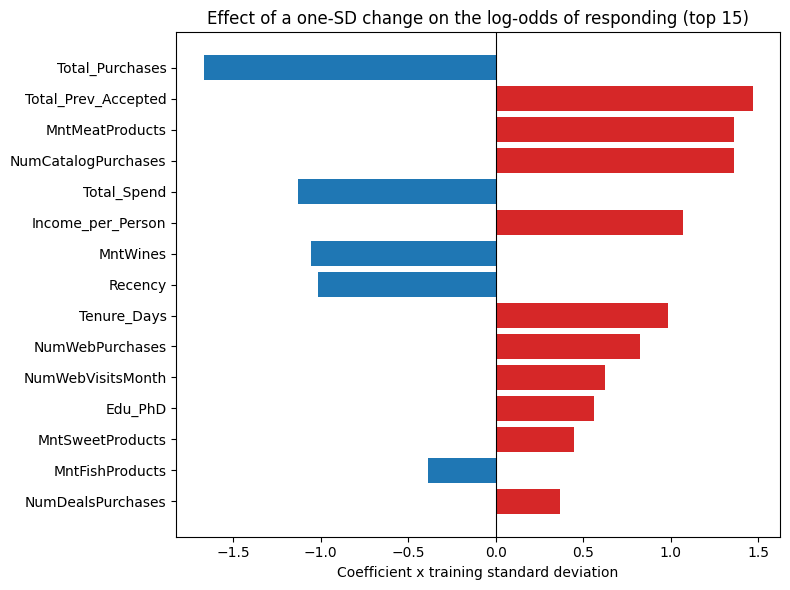

In [29]:
# Coefficient-based importance. The model is linear, so each coefficient is the feature's effect on the log-odds.
coefs = pd.Series(model.coef_[0], index=feature_names)
train_sd = X_train.std()

coef_table = pd.DataFrame({
    "Coefficient": coefs,
    "Odds ratio": np.exp(coefs),
    "Training SD": train_sd,
    "Coefficient x SD": coefs * train_sd,
})
coef_table["Direction"] = np.where(coef_table["Coefficient x SD"] > 0, "Raises response", "Lowers response")
coef_table = coef_table.reindex(coef_table["Coefficient x SD"].abs().sort_values(ascending=False).index)
display(coef_table.round(3))

# Chart: the 15 largest effects, red = raises the chance of responding, blue = lowers it
top_coef = coef_table.head(15).iloc[::-1]
plt.figure(figsize=(8, 6))
plt.barh(top_coef.index, top_coef["Coefficient x SD"],
         color=np.where(top_coef["Coefficient x SD"] > 0, "tab:red", "tab:blue"))
plt.axvline(0, color="black", lw=0.8)
plt.title("Effect of a one-SD change on the log-odds of responding (top 15)")
plt.xlabel("Coefficient x training standard deviation")
plt.tight_layout()
plt.savefig(FIG_DIR / "week11_coefficients.png", dpi=150)
plt.show()

### Interpretation: coefficients

- **Largest effects** (log-odds per one standard deviation):
  - `Total_Purchases` (−1.67), `Total_Prev_Accepted` (+1.47), `MntMeatProducts` (+1.36), `NumCatalogPurchases` (+1.36), `Total_Spend` (−1.13), `Income_per_Person` (+1.07), `MntWines` (−1.05), `Recency` (−1.02) and `Tenure_Days` (+0.98).
- **Previous campaign acceptance** is the clearest single driver. One additional accepted campaign is a step of about 1.44 in the standardized column, so it multiplies the odds of responding by about exp(1.508 × 1.437) ≈ 8.7.
- **Recency is negative:** customers who purchased longer ago are less likely to respond.
- **Tenure is positive:** longer-standing customers are more likely to respond.
- **The negative signs on `Total_Purchases`, `Total_Spend` and `MntWines` should not be read on their own.** These features are strongly correlated with meat and catalog spending (see the correlation table below). In a linear model, correlated features share the effect, and some take negative values that correct for the others. Overall, higher-spending customers still respond more often (Week 10 found a 30% response rate in the top income-per-person quartile against 8% in the bottom).
- **Demographic features have modest coefficients,** with one exception: `Edu_PhD` (odds ratio 3.9, but only 0.56 log-odds per typical change, since it is a 0/1 flag held by 22% of customers).

,PR-AUC drop (mean),PR-AUC drop (std)
Total_Prev_Accepted,0.3594,0.0408
NumCatalogPurchases,0.2218,0.0332
Income_per_Person,0.1856,0.0362
MntMeatProducts,0.1822,0.0288
Total_Purchases,0.1747,0.0325
Recency,0.1551,0.0206
Total_Spend,0.1042,0.0259
MntWines,0.0998,0.0225
Tenure_Days,0.0969,0.0356
NumWebPurchases,0.0709,0.0286


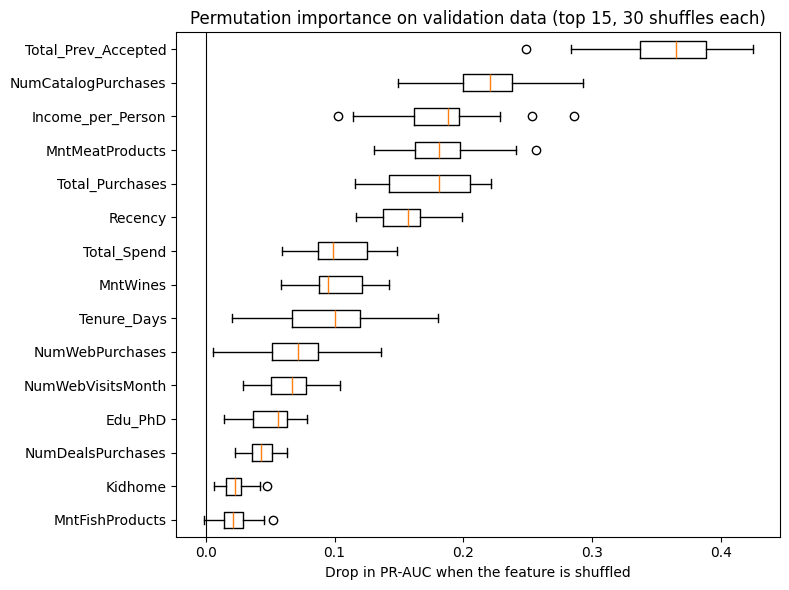

In [30]:
# Permutation importance on the validation data (not used for fitting), scored with PR-AUC as in Week 10.
# Each feature is shuffled 30 times; the mean and spread of the PR-AUC drop are reported.
perm = permutation_importance(
    model, X_val, y_val,
    scoring="average_precision",
    n_repeats=30,
    random_state=RANDOM_STATE,
)
perm_table = pd.DataFrame({
    "PR-AUC drop (mean)": perm.importances_mean,
    "PR-AUC drop (std)": perm.importances_std,
}, index=feature_names).sort_values("PR-AUC drop (mean)", ascending=False)
display(perm_table.round(4))

# Box plot of the 30 shuffles for the 15 most important features
top_perm = perm_table.head(15).index[::-1]
order_idx = [feature_names.index(f) for f in top_perm]
plt.figure(figsize=(8, 6))
plt.boxplot(perm.importances[order_idx].T, vert=False)
plt.yticks(range(1, len(top_perm) + 1), list(top_perm))
plt.axvline(0, color="black", lw=0.8)
plt.title("Permutation importance on validation data (top 15, 30 shuffles each)")
plt.xlabel("Drop in PR-AUC when the feature is shuffled")
plt.tight_layout()
plt.savefig(FIG_DIR / "week11_permutation_importance.png", dpi=150)
plt.show()

### Interpretation: permutation importance

- **What drives performance:** shuffling `Total_Prev_Accepted` lowers validation PR-AUC by 0.36, by far the largest drop. Next come `NumCatalogPurchases` (0.22), `Income_per_Person` (0.19), `MntMeatProducts` (0.18), `Total_Purchases` (0.17) and `Recency` (0.16). The model's performance rests mostly on past campaign behavior, catalog engagement, spending and income relative to household size.
- **Demographic features contribute almost nothing:** `Age` (−0.001), `Is_Partnered` (0.005), `Teenhome` (0.001), `Lives_Alone` (0.003), `Edu_Master` (0.000) and `Edu_Graduation` (0.004). `Kidhome` (0.023) and `Edu_PhD` (0.051) are small exceptions. This matters for Part 4: removing the sensitive features should cost little accuracy, as long as their information does not reach the model through other features.

In [31]:
# Compare the two rankings. Features ranked high by coefficient but low by permutation usually share
# their information with correlated features: shuffling one leaves the others to carry the signal.
ranks = pd.DataFrame({
    "Rank by |coefficient x SD|": coef_table["Coefficient x SD"].abs().rank(ascending=False),
    "Rank by permutation": perm_table["PR-AUC drop (mean)"].rank(ascending=False),
})
ranks["Rank difference"] = ranks["Rank by |coefficient x SD|"] - ranks["Rank by permutation"]
ranks = ranks.sort_values("Rank by |coefficient x SD|")
display(ranks.head(15).astype(int))
print("Spearman correlation between the two rankings:",
      round(ranks["Rank by |coefficient x SD|"].corr(ranks["Rank by permutation"], method="spearman"), 3))

# Strongly correlated pairs among the 12 largest-coefficient features (|r| > 0.7 on training data)
top_feats = coef_table.head(12).index
corr = X_train[top_feats].corr()
pairs = [
    {"Feature A": a, "Feature B": b, "Correlation": corr.loc[a, b]}
    for i, a in enumerate(top_feats) for b in top_feats[i + 1:]
    if abs(corr.loc[a, b]) > 0.7
]
if pairs:
    display(pd.DataFrame(pairs).sort_values("Correlation", key=abs, ascending=False).round(3))
else:
    print("No pair among the top 12 features has |correlation| > 0.7")

,Rank by |coefficient x SD|,Rank by permutation,Rank difference
Total_Purchases,1,5,-4
Total_Prev_Accepted,2,1,1
MntMeatProducts,3,4,-1
NumCatalogPurchases,4,2,2
Total_Spend,5,7,-2
Income_per_Person,6,3,3
MntWines,7,8,-1
Recency,8,6,2
Tenure_Days,9,9,0
NumWebPurchases,10,10,0


Spearman correlation between the two rankings: 0.871


,Feature A,Feature B,Correlation
6,MntMeatProducts,Total_Spend,0.939
10,Total_Spend,MntWines,0.929
2,Total_Purchases,Total_Spend,0.908
8,NumCatalogPurchases,Total_Spend,0.888
1,Total_Purchases,NumCatalogPurchases,0.874
3,Total_Purchases,MntWines,0.853
0,Total_Purchases,MntMeatProducts,0.850
5,MntMeatProducts,NumCatalogPurchases,0.841
7,MntMeatProducts,MntWines,0.833
9,NumCatalogPurchases,MntWines,0.810


### Interpretation: agreement between the two methods

- **The two rankings mostly agree** (Spearman correlation 0.87), and the top nine features are the same in both.
- **The largest disagreement is `MntSweetProducts`:** it ranks 13th by coefficient but last by permutation. Its coefficient is not negligible, yet shuffling it leaves performance unchanged, so its information is redundant with other spending features.
- **The spending and purchase features are highly correlated** (r = 0.81 to 0.94), which explains the offsetting signs in the coefficient table. Their *combined* effect is more meaningful than any single coefficient.

## Part 2: Explaining Five Individual Predictions

For a logistic regression, each prediction can be split exactly into per-feature contributions:

log-odds(customer) = log-odds(average customer) + Σ coefficientⱼ × (valueⱼ − training meanⱼ)

Each term shows how much that feature moves this customer away from the average customer. A positive contribution raises the probability of responding. These are the same values the SHAP linear explainer produces for a linear model, so no extra package is needed.

Five test customers are explained, chosen to cover each kind of outcome:

1. **Confident correct responder:** the highest-scored customer who responded.
2. **Confident correct non-responder:** the lowest-scored customer who did not respond.
3. **Worst false alarm:** the highest-scored customer who did *not* respond.
4. **Worst missed responder:** the lowest-scored customer who *did* respond.
5. **Borderline case:** the customer whose probability is closest to 0.5.

In [32]:
# Per-feature contributions for every test customer, measured against the average training customer
train_mean = X_train.mean()
intercept = model.intercept_[0]
base_logit = intercept + float((coefs * train_mean).sum())     # log-odds of the average training customer

contrib_test = (X_test - train_mean) * coefs                    # one column per feature
logit_test = base_logit + contrib_test.sum(axis=1)

# Check: contributions must add up exactly to the model's own log-odds
assert np.allclose(logit_test.to_numpy(), model.decision_function(X_test)), "Contributions do not add up"
proba_test = model.predict_proba(X_test)[:, 1]

# The top-40% targeting cutoff on the test data, used to say whether each customer would be contacted
target_cutoff = np.sort(proba_test)[::-1][int(np.ceil(TOP_SHARE * len(proba_test))) - 1]
print(f"Average customer: log-odds {base_logit:.3f}, probability {1 / (1 + np.exp(-base_logit)):.3f}")
print(f"Probability needed to be in the top 40% of test customers: {target_cutoff:.3f}")

Average customer: log-odds -3.317, probability 0.035
Probability needed to be in the top 40% of test customers: 0.046


In [33]:
# Select the five customers. Each rule searches only customers not already chosen.
y_test_arr = y_test.to_numpy()
chosen = {}

def pick(label, mask, highest):
    # Returns the index of the highest- or lowest-probability customer within mask
    mask = mask & ~np.isin(np.arange(len(y_test_arr)), list(chosen.values()))
    if not mask.any():
        print(f"No customer available for: {label}")
        return
    idx = np.where(mask)[0]
    chosen[label] = idx[np.argmax(proba_test[idx])] if highest else idx[np.argmin(proba_test[idx])]

pick("1. Confident correct responder", (y_test_arr == 1) & (proba_test >= 0.5), highest=True)
pick("2. Confident correct non-responder", (y_test_arr == 0) & (proba_test < 0.5), highest=False)
pick("3. Worst false alarm", (y_test_arr == 0), highest=True)
pick("4. Worst missed responder", (y_test_arr == 1), highest=False)

# Borderline: closest to 0.5 among the remaining customers
remaining = ~np.isin(np.arange(len(y_test_arr)), list(chosen.values()))
idx = np.where(remaining)[0]
chosen["5. Borderline case"] = idx[np.argmin(np.abs(proba_test[idx] - 0.5))]

case_summary = pd.DataFrame([
    {
        "Case": label,
        "Test row": i,
        "Predicted probability": proba_test[i],
        "Prediction at 0.5": "Respond" if proba_test[i] >= 0.5 else "No response",
        "Contacted (top 40%)": "Yes" if proba_test[i] >= target_cutoff else "No",
        "Actual": "Responded" if y_test_arr[i] == 1 else "Did not respond",
    }
    for label, i in chosen.items()
]).set_index("Case")
display(case_summary.round(3))

,Test row,Predicted probability,Prediction at 0.5,Contacted (top 40%),Actual
Case,,,,,
1. Confident correct responder,262,1.000,Respond,Yes,Responded
2. Confident correct non-responder,336,0.000,No response,No,Did not respond
3. Worst false alarm,48,0.873,Respond,Yes,Did not respond
4. Worst missed responder,366,0.008,No response,No,Responded
5. Borderline case,394,0.498,No response,Yes,Responded


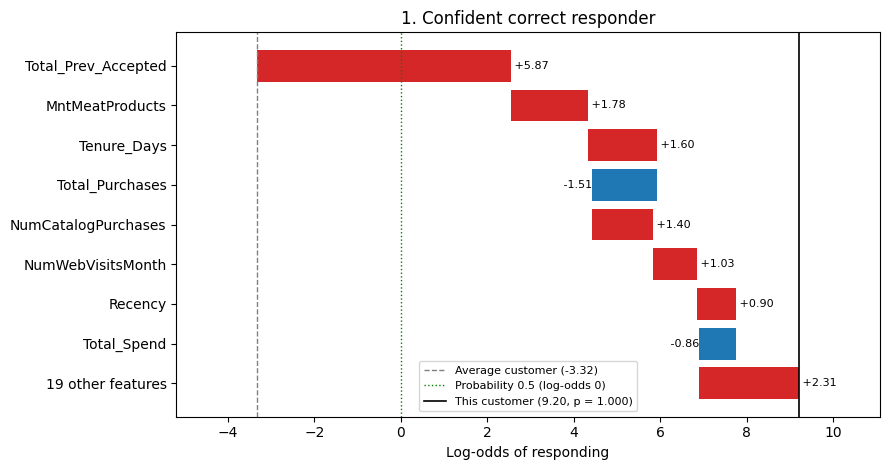

,Customer value,Training mean,Contribution (log-odds)
Total_Prev_Accepted,3.869,-0.020,5.866
MntMeatProducts,1.273,-0.018,1.783
Tenure_Days,1.627,-0.003,1.600
Total_Purchases,0.881,-0.018,-1.509
NumCatalogPurchases,0.995,-0.015,1.398
NumWebVisitsMonth,1.576,0.013,1.032
Recency,-0.895,-0.009,0.901
Total_Spend,0.737,-0.023,-0.862


Predicted probability 1.000; contacted under the top-40% rule: yes; actual: responded
Largest factors raising the score: Total_Prev_Accepted (+5.87), MntMeatProducts (+1.78), Tenure_Days (+1.60)
Largest factors lowering the score: Total_Purchases (-1.51), Total_Spend (-0.86)


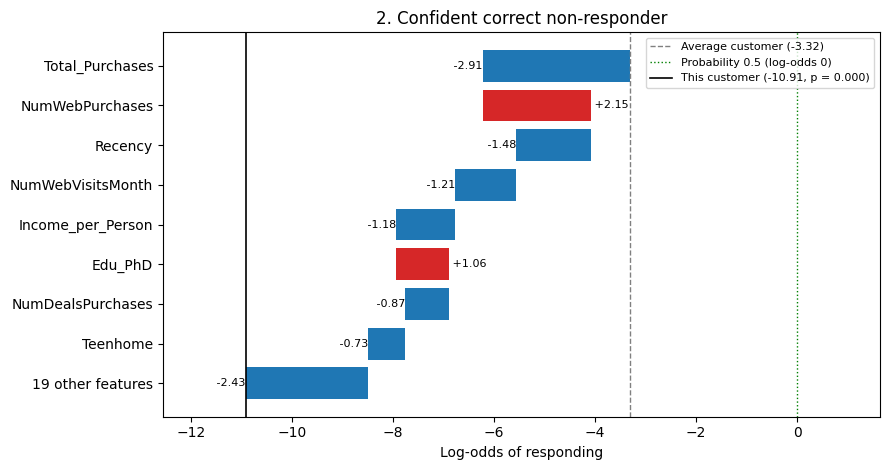

,Customer value,Training mean,Contribution (log-odds)
Total_Purchases,1.714,-0.018,-2.909
NumWebPurchases,2.559,-0.007,2.148
Recency,1.449,-0.009,-1.483
NumWebVisitsMonth,-1.815,0.013,-1.207
Income_per_Person,-1.085,-0.030,-1.178
Edu_PhD,1.000,0.222,1.056
NumDealsPurchases,-2.313,0.005,-0.874
Teenhome,2.736,0.018,-0.725


Predicted probability 0.000; contacted under the top-40% rule: no; actual: did not respond
Largest factors raising the score: NumWebPurchases (+2.15), Edu_PhD (+1.06)
Largest factors lowering the score: Total_Purchases (-2.91), Recency (-1.48), NumWebVisitsMonth (-1.21)


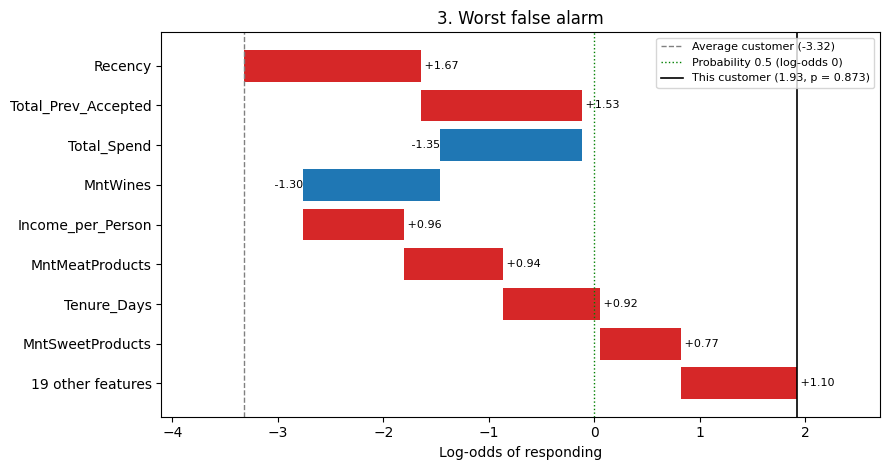

,Customer value,Training mean,Contribution (log-odds)
Recency,-1.654,-0.009,1.672
Total_Prev_Accepted,0.995,-0.020,1.530
Total_Spend,1.165,-0.023,-1.347
MntWines,1.210,-0.024,-1.301
Income_per_Person,0.828,-0.030,0.958
MntMeatProducts,0.666,-0.018,0.944
Tenure_Days,0.932,-0.003,0.917
MntSweetProducts,1.670,-0.013,0.765


Predicted probability 0.873; contacted under the top-40% rule: yes; actual: did not respond
Largest factors raising the score: Recency (+1.67), Total_Prev_Accepted (+1.53), Income_per_Person (+0.96)
Largest factors lowering the score: Total_Spend (-1.35), MntWines (-1.30)


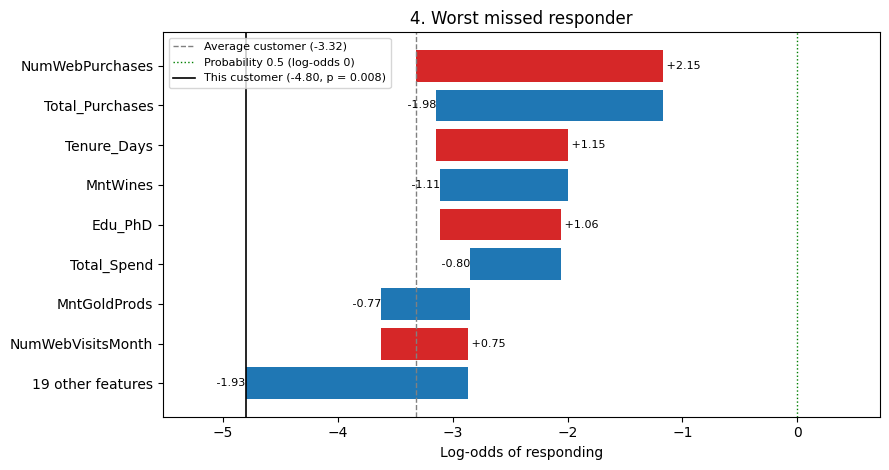

,Customer value,Training mean,Contribution (log-odds)
NumWebPurchases,2.559,-0.007,2.148
Total_Purchases,1.158,-0.018,-1.976
Tenure_Days,1.165,-0.003,1.146
MntWines,1.030,-0.024,-1.112
Edu_PhD,1.000,0.222,1.056
Total_Spend,0.680,-0.023,-0.796
MntGoldProds,-2.441,-0.011,-0.771
NumWebVisitsMonth,1.152,0.013,0.752


Predicted probability 0.008; contacted under the top-40% rule: no; actual: responded
Largest factors raising the score: NumWebPurchases (+2.15), Tenure_Days (+1.15), Edu_PhD (+1.06)
Largest factors lowering the score: Total_Purchases (-1.98), MntWines (-1.11), Total_Spend (-0.80)


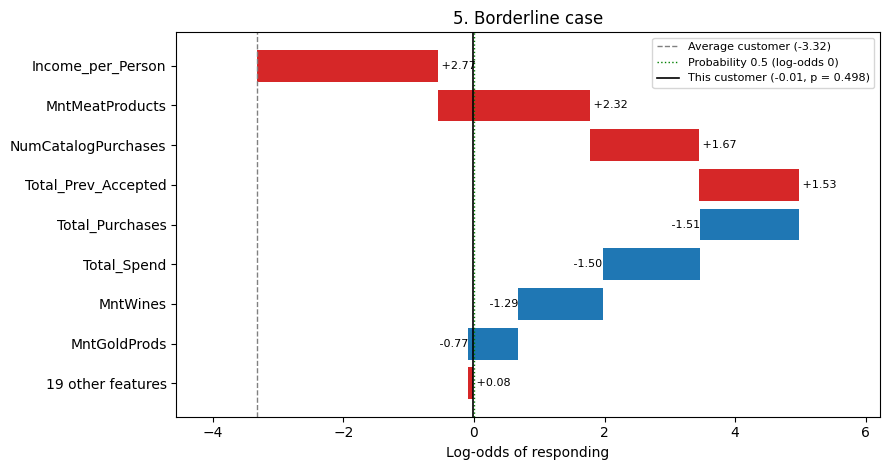

,Customer value,Training mean,Contribution (log-odds)
Income_per_Person,2.452,-0.030,2.771
MntMeatProducts,1.660,-0.018,2.318
NumCatalogPurchases,1.194,-0.015,1.673
Total_Prev_Accepted,0.995,-0.020,1.530
Total_Purchases,0.881,-0.018,-1.509
Total_Spend,1.298,-0.023,-1.497
MntWines,1.197,-0.024,-1.287
MntGoldProds,-2.441,-0.011,-0.771


Predicted probability 0.498; contacted under the top-40% rule: yes; actual: responded
Largest factors raising the score: Income_per_Person (+2.77), MntMeatProducts (+2.32), NumCatalogPurchases (+1.67)
Largest factors lowering the score: Total_Purchases (-1.51), Total_Spend (-1.50), MntWines (-1.29)


In [34]:
# Waterfall chart and plain-language summary for each chosen customer.
# Bars start from the average customer's log-odds and add each feature's contribution in turn.
def explain_customer(label, i, top_n=8):
    row = contrib_test.iloc[i]
    order = row.abs().sort_values(ascending=False).index
    top = row[order[:top_n]]
    rest = row[order[top_n:]].sum()
    items = list(top.items()) + [(f"{len(order) - top_n} other features", rest)]
    final_logit = logit_test.iloc[i]

    fig, ax = plt.subplots(figsize=(9, 4.8))
    running = base_logit
    for k, (name, value) in enumerate(items):
        ax.barh(k, value, left=running, color="tab:red" if value > 0 else "tab:blue")
        ax.text(running + value, k, f" {value:+.2f}", va="center",
                ha="left" if value >= 0 else "right", fontsize=8)
        running += value
    positions = np.concatenate([[base_logit, final_logit, 0.0], base_logit + np.cumsum([v for _, v in items])])
    lo, hi = positions.min(), positions.max()
    pad = 0.15 * (hi - lo)
    ax.set_xlim(lo - pad, hi + pad)
    ax.axvline(base_logit, color="gray", ls="--", lw=1, label=f"Average customer ({base_logit:.2f})")
    ax.axvline(0, color="green", ls=":", lw=1, label="Probability 0.5 (log-odds 0)")
    ax.axvline(final_logit, color="black", lw=1.2,
               label=f"This customer ({final_logit:.2f}, p = {proba_test[i]:.3f})")
    ax.set_yticks(range(len(items)))
    ax.set_yticklabels([name for name, _ in items])
    ax.invert_yaxis()
    ax.set_xlabel("Log-odds of responding")
    ax.set_title(label)
    ax.legend(fontsize=8, loc="best")
    plt.tight_layout()
    plt.show()

    # Table: the customer's feature values (in SD units or 0/1) next to their contributions
    detail = pd.DataFrame({
        "Customer value": X_test.iloc[i][order[:top_n]],
        "Training mean": train_mean[order[:top_n]],
        "Contribution (log-odds)": top,
    })
    display(detail.round(3))

    raises = [f"{f} ({v:+.2f})" for f, v in top.items() if v > 0][:3]
    lowers = [f"{f} ({v:+.2f})" for f, v in top.items() if v < 0][:3]
    print(f"Predicted probability {proba_test[i]:.3f}; contacted under the top-40% rule: "
          f"{'yes' if proba_test[i] >= target_cutoff else 'no'}; actual: "
          f"{'responded' if y_test_arr[i] == 1 else 'did not respond'}")
    print("Largest factors raising the score:", ", ".join(raises) if raises else "none")
    print("Largest factors lowering the score:", ", ".join(lowers) if lowers else "none")


for label, i in chosen.items():
    explain_customer(label, i)

### Interpretation: the five predictions

Contributions are in log-odds relative to the average training customer, whose predicted probability is 0.035. Feature values are in standard deviations from the training mean. Under the top-40% rule, a test customer is contacted if their predicted probability is at least 0.046.

1. **Confident correct responder (p = 1.000, responded).**
   - Three previous campaign acceptances add +5.87 log-odds, which on its own outweighs every other feature.
   - High meat spending (+1.78), long tenure (+1.60), frequent catalog purchases (+1.40), frequent web visits (+1.03) and a recent purchase (+0.90) add to it.
   - This is the model's clearest responder profile: a loyal, engaged customer who has accepted offers before.
2. **Confident correct non-responder (p = 0.000, did not respond).**
   - The score is pulled down by a long gap since the last purchase (Recency +1.45 SD → −1.48), few web visits (−1.21), low income per person (−1.18), few deal purchases (−0.87) and teenagers at home (−0.73).
   - `Total_Purchases` (−2.91) also lowers the score, through the offsetting effect described in Part 1.
   - Heavy web purchasing (+2.15) and a PhD (+1.06) raise the score but cannot compensate.
3. **Worst false alarm (p = 0.873, did not respond).**
   - A very recent purchase (+1.67), one previous acceptance (+1.53), above-average income per person (+0.96), and meat and sweets spending raise the score.
   - This matches the false-alarm profile from the Week 10 error analysis: engaged, recent, high-spending customers who still did not respond.
   - The data contains no feature that separates this customer from true responders.
4. **Worst missed responder (p = 0.008, responded).**
   - The positive signals are web purchases (+2.15), tenure (+1.15) and a PhD (+1.06).
   - They are outweighed by the offsetting purchase and spending terms (−1.98, −1.11, −0.80) and very low gold spending (−0.77).
   - Previous campaign acceptance, the strongest signal in the model, does not appear among the positive drivers. Week 10 found the same pattern: responders with no acceptance history are the hardest to find.
5. **Borderline case (p = 0.498, responded).**
   - High income per person (+2.77), meat spending (+2.32), catalog purchases (+1.67) and one previous acceptance (+1.53) are almost exactly balanced by the offsetting spending terms.
   - At the 0.5 cutoff, this responder would be classified as "no response." Under the top-40% rule actually used by the campaign, the customer is contacted, which shows why the ranking rule finds more responders than a fixed 0.5 threshold.

### Five randomly selected predictions and what would flip them

Five test customers are drawn at random (fixed seed, so the draw is reproducible). For each one, the chart and table show which features drove the prediction. The flip table shows the smallest **single-feature** changes that would move the prediction across the 0.5 cutoff, from "no response" to "respond" or the reverse.

- **How the required change is computed:** the model predicts "respond" when the log-odds are at least 0, so the required log-odds change is −(current log-odds). Dividing it by a feature's coefficient gives the change in that feature that would flip the prediction on its own.
- **Which changes are kept:** only changes that keep the feature inside the range observed in the training data. Binary flags can only switch between 0 and 1.
- **Units:** changes are in standard deviations (SD), because the data is standardized.
- **Each change assumes every other feature stays fixed.** For strongly correlated features, such as the spending columns, that is a simplification: in practice, a customer who spends more on meat usually also has higher total spend.

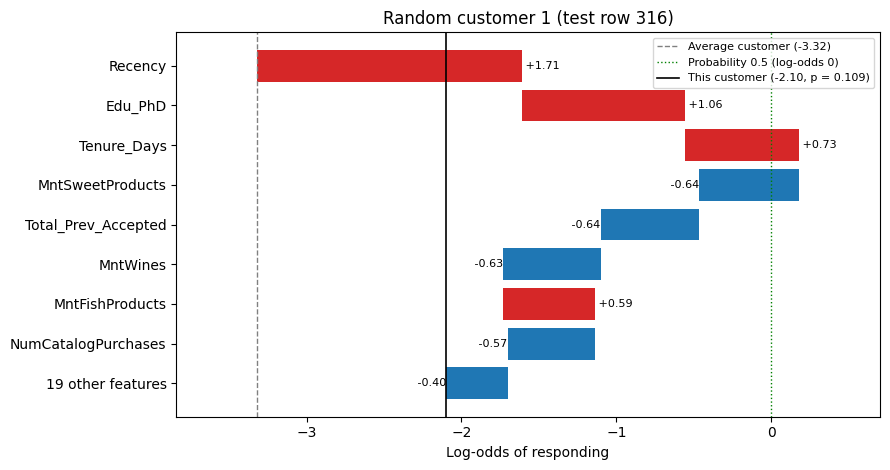

,Customer value,Training mean,Contribution (log-odds)
Recency,-1.688,-0.009,1.707
Edu_PhD,1.000,0.222,1.056
Tenure_Days,0.743,-0.003,0.732
MntSweetProducts,-1.426,-0.013,-0.643
Total_Prev_Accepted,-0.442,-0.020,-0.637
MntWines,0.570,-0.024,-0.627
MntFishProducts,-1.536,-0.005,0.594
NumCatalogPurchases,-0.424,-0.015,-0.566


Predicted probability 0.109; contacted under the top-40% rule: yes; actual: did not respond
Largest factors raising the score: Recency (+1.71), Edu_PhD (+1.06), Tenure_Days (+0.73)
Largest factors lowering the score: MntSweetProducts (-0.64), Total_Prev_Accepted (-0.64), MntWines (-0.63)
To flip from 'no response' to 'respond', the log-odds must change by +2.10.
Smallest single-feature changes that would do it (within the observed training range):


,Current value,Required change,New value,Change in SDs
Feature,,,,
Total_Purchases,0.186,-1.250,-1.064,1.258
Total_Prev_Accepted,-0.442,1.391,0.949,1.430
MntMeatProducts,0.084,1.519,1.602,1.540
NumCatalogPurchases,-0.424,1.517,1.092,1.543
Total_Spend,0.239,-1.851,-1.612,1.859
Income_per_Person,-0.441,1.880,1.439,1.957


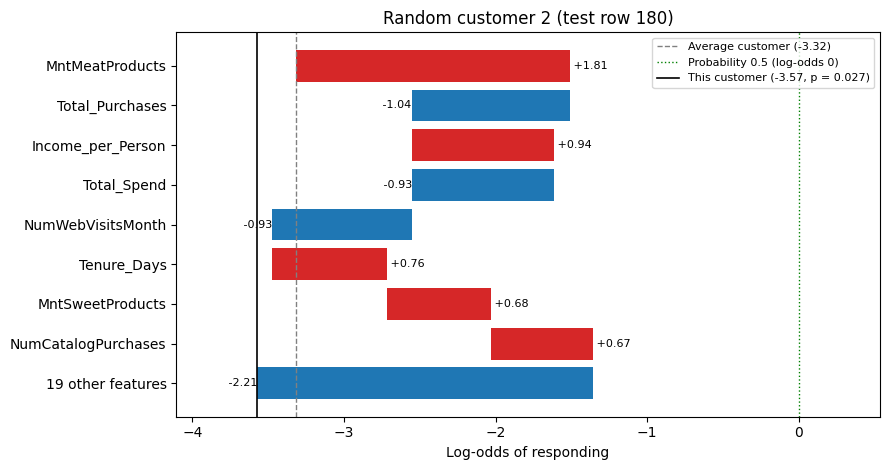

,Customer value,Training mean,Contribution (log-odds)
MntMeatProducts,1.290,-0.018,1.807
Total_Purchases,0.603,-0.018,-1.042
Income_per_Person,0.811,-0.030,0.939
Total_Spend,0.802,-0.023,-0.935
NumWebVisitsMonth,-1.391,0.013,-0.927
Tenure_Days,0.773,-0.003,0.761
MntSweetProducts,1.488,-0.013,0.682
NumCatalogPurchases,0.471,-0.015,0.673


Predicted probability 0.027; contacted under the top-40% rule: no; actual: did not respond
Largest factors raising the score: MntMeatProducts (+1.81), Income_per_Person (+0.94), Tenure_Days (+0.76)
Largest factors lowering the score: Total_Purchases (-1.04), Total_Spend (-0.93), NumWebVisitsMonth (-0.93)
To flip from 'no response' to 'respond', the log-odds must change by +3.57.
Smallest single-feature changes that would do it (within the observed training range):


,Current value,Required change,New value,Change in SDs
Feature,,,,
Total_Prev_Accepted,-0.442,2.367,1.925,2.433


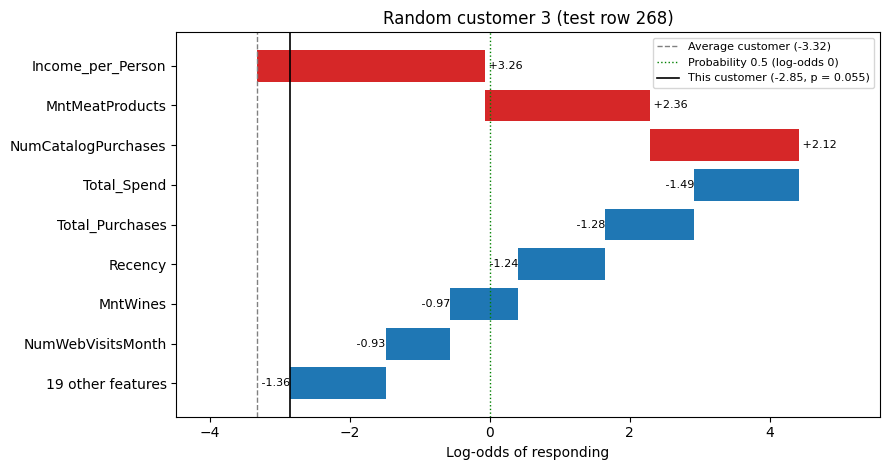

,Customer value,Training mean,Contribution (log-odds)
Income_per_Person,2.887,-0.030,3.256
MntMeatProducts,1.687,-0.018,2.355
NumCatalogPurchases,1.519,-0.015,2.123
Total_Spend,1.293,-0.023,-1.492
Total_Purchases,0.742,-0.018,-1.276
Recency,1.208,-0.009,-1.238
MntWines,0.896,-0.024,-0.971
NumWebVisitsMonth,-1.391,0.013,-0.927


Predicted probability 0.055; contacted under the top-40% rule: yes; actual: did not respond
Largest factors raising the score: Income_per_Person (+3.26), MntMeatProducts (+2.36), NumCatalogPurchases (+2.12)
Largest factors lowering the score: Total_Spend (-1.49), Total_Purchases (-1.28), Recency (-1.24)
To flip from 'no response' to 'respond', the log-odds must change by +2.85.
Smallest single-feature changes that would do it (within the observed training range):


,Current value,Required change,New value,Change in SDs
Feature,,,,
Total_Purchases,0.742,-1.698,-0.956,1.710
Total_Prev_Accepted,-0.442,1.890,1.448,1.943
Total_Spend,1.293,-2.515,-1.222,2.525
MntWines,0.896,-2.703,-1.807,2.704
Recency,1.208,-2.803,-1.596,2.808


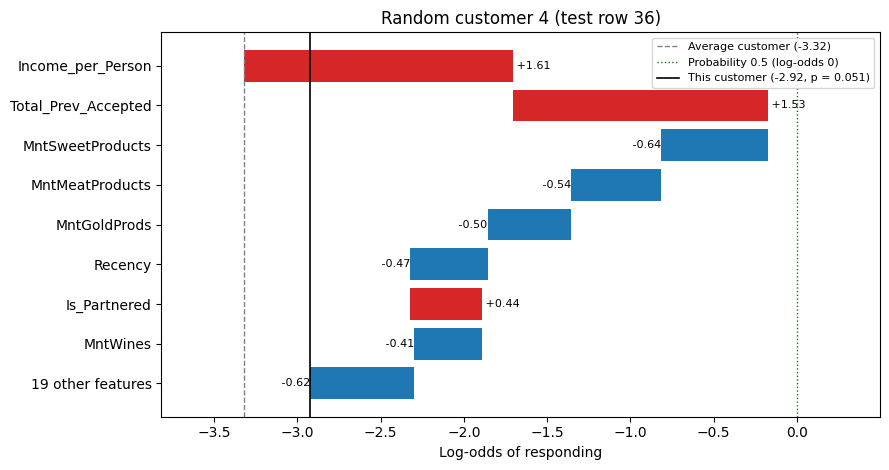

,Customer value,Training mean,Contribution (log-odds)
Income_per_Person,1.417,-0.030,1.614
Total_Prev_Accepted,0.995,-0.020,1.530
MntSweetProducts,-1.426,-0.013,-0.643
MntMeatProducts,-0.411,-0.018,-0.543
MntGoldProds,-1.584,-0.011,-0.499
Recency,0.449,-0.009,-0.466
Is_Partnered,0.000,0.649,0.436
MntWines,0.365,-0.024,-0.410


Predicted probability 0.051; contacted under the top-40% rule: yes; actual: did not respond
Largest factors raising the score: Income_per_Person (+1.61), Total_Prev_Accepted (+1.53), Is_Partnered (+0.44)
Largest factors lowering the score: MntSweetProducts (-0.64), MntMeatProducts (-0.54), MntGoldProds (-0.50)
To flip from 'no response' to 'respond', the log-odds must change by +2.92.
Smallest single-feature changes that would do it (within the observed training range):


,Current value,Required change,New value,Change in SDs
Feature,,,,
Total_Prev_Accepted,0.995,1.937,2.932,1.992


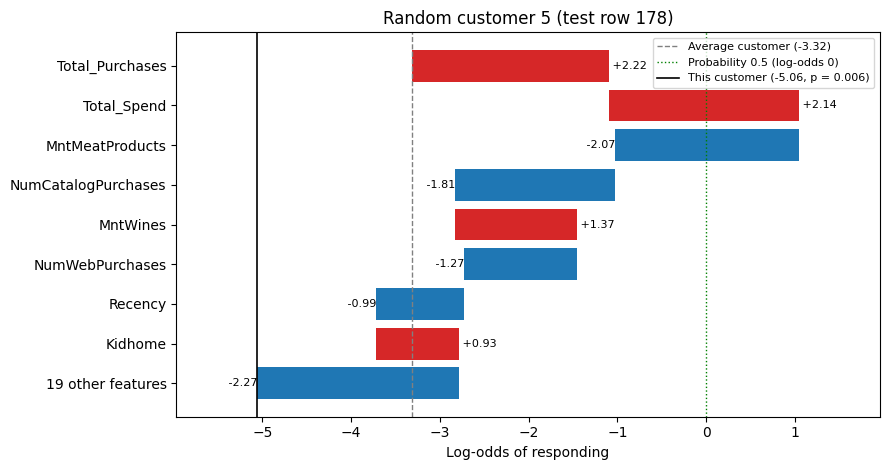

,Customer value,Training mean,Contribution (log-odds)
Total_Purchases,-1.342,-0.018,2.223
Total_Spend,-1.910,-0.023,2.139
MntMeatProducts,-1.513,-0.018,-2.066
NumCatalogPurchases,-1.320,-0.015,-1.806
MntWines,-1.324,-0.024,1.371
NumWebPurchases,-1.524,-0.007,-1.270
Recency,0.966,-0.009,-0.992
Kidhome,2.856,0.005,0.927


Predicted probability 0.006; contacted under the top-40% rule: no; actual: did not respond
Largest factors raising the score: Total_Purchases (+2.22), Total_Spend (+2.14), MntWines (+1.37)
Largest factors lowering the score: MntMeatProducts (-2.07), NumCatalogPurchases (-1.81), NumWebPurchases (-1.27)
To flip from 'no response' to 'respond', the log-odds must change by +5.06.
Smallest single-feature changes that would do it (within the observed training range):


,Current value,Required change,New value,Change in SDs
Feature,,,,
Total_Prev_Accepted,-0.442,3.352,2.91,3.446


,Predicted probability,Prediction at 0.5,Contacted (top 40%),Actual,Log-odds change to flip,Easiest flip
Customer,,,,,,
Random customer 1 (test row 316),0.109,no response,Yes,Did not respond,2.098,Total_Purchases (-1.25)
Random customer 2 (test row 180),0.027,no response,No,Did not respond,3.571,Total_Prev_Accepted (+2.37)
Random customer 3 (test row 268),0.055,no response,Yes,Did not respond,2.851,Total_Purchases (-1.70)
Random customer 4 (test row 36),0.051,no response,Yes,Did not respond,2.922,Total_Prev_Accepted (+1.94)
Random customer 5 (test row 178),0.006,no response,No,Did not respond,5.056,Total_Prev_Accepted (+3.35)


In [35]:
# Five randomly drawn test customers: contributions chart, plus the single-feature changes that would flip each prediction
rng = np.random.default_rng(RANDOM_STATE)
random_rows = rng.choice(len(X_test), size=5, replace=False)

binary_cols = [c for c in feature_names if X_train[c].nunique() <= 2]
train_min, train_max = X_train.min(), X_train.max()


def flip_table(i, top_n=6):
    # Smallest single-feature changes (within the training range) that move the prediction across the 0.5 cutoff
    needed = 0.0 - logit_test.iloc[i]                  # log-odds change required; log-odds 0 = probability 0.5
    rows = []
    for f in feature_names:
        x, b = X_test.iloc[i][f], coefs[f]
        if b == 0:
            continue
        if f in binary_cols:
            delta = 1 - 2 * round(x)                   # a flag can only switch 0 -> 1 or 1 -> 0
            if b * delta * np.sign(needed) < abs(needed):
                continue                               # switching the flag is not enough (or moves the wrong way)
        else:
            delta = needed / b
            if not (train_min[f] <= x + delta <= train_max[f]):
                continue                               # the required value was never observed in the training data
        rows.append({
            "Feature": f,
            "Current value": x,
            "Required change": delta,
            "New value": x + delta,
            "Change in SDs": abs(delta) / train_sd[f],
        })
    if not rows:
        return pd.DataFrame(columns=["Current value", "Required change", "New value", "Change in SDs"])
    return pd.DataFrame(rows).set_index("Feature").sort_values("Change in SDs").head(top_n)


random_summary = []
for k, i in enumerate(random_rows, start=1):
    label = f"Random customer {k} (test row {i})"
    explain_customer(label, i)

    needed = -logit_test.iloc[i]
    current_class = "respond" if proba_test[i] >= 0.5 else "no response"
    target_class = "no response" if current_class == "respond" else "respond"
    flips = flip_table(i)
    print(f"To flip from '{current_class}' to '{target_class}', the log-odds must change by {needed:+.2f}.")
    print("Smallest single-feature changes that would do it (within the observed training range):")
    display(flips.round(3))

    random_summary.append({
        "Customer": label,
        "Predicted probability": proba_test[i],
        "Prediction at 0.5": current_class,
        "Contacted (top 40%)": "Yes" if proba_test[i] >= target_cutoff else "No",
        "Actual": "Responded" if y_test_arr[i] == 1 else "Did not respond",
        "Log-odds change to flip": needed,
        "Easiest flip": f"{flips.index[0]} ({flips['Required change'].iloc[0]:+.2f})" if len(flips) else "none in range",
    })

display(pd.DataFrame(random_summary).set_index("Customer").round(3))

### Interpretation: five random predictions

- **All five are true negatives:** each has a predicted probability below 0.5 and did not respond, as expected when 85% of customers do not respond. Three of them (customers 1, 3 and 4) are still contacted under the top-40% rule, because the campaign ranks customers instead of using the 0.5 cutoff.
- **The smallest change that flips the prediction is more accepted campaigns in four of the five cases.** One previous acceptance is a step of 1.44 SD in `Total_Prev_Accepted`. In customer 1, the step from none to one acceptance (+1.44 SD) exceeds the +1.39 SD needed, so one acceptance would flip the prediction. Customers 2 and 3 would need two acceptances, customer 4 two more on top of the one already recorded, and customer 5 three. This confirms how heavily the model relies on campaign history.
- **No prediction is close to the boundary:** every flip needs a log-odds change between +2.10 and +5.06, or at least 1.25 SD in a single feature.
- **Customer 4's "not partnered" status adds +0.44 log-odds,** a direct contribution from a protected attribute, although it does not decide the prediction.
- **Single-feature changes are a simplification for the spending features.** Because they are strongly correlated, a customer who spends more on meat usually also has higher total spend, which partly offsets the change. Negative "required changes" for `Total_Purchases` and `Total_Spend` reflect the offsetting coefficients described in Part 1, not a realistic way to raise response.

## Part 3: Bias Analysis

### Customer groups examined

The groups below are formed from attributes that are personal or demographic, or that could lead to unfair treatment if the model systematically leaves a group out of the campaign:

| Attribute | Groups | Why it matters |
|---|---|---|
| Age | Quartiles (Q1 youngest to Q4 oldest) | Age is a protected characteristic in many settings; excluding older or younger customers from offers is a fairness concern. |
| Income | Quartiles (Q1 lowest to Q4 highest) | Socioeconomic status: low-income customers could be systematically excluded from discounts. |
| Partner status | Partnered / not partnered | Marital and family status are protected in some contexts (for example credit offers). |
| Children at home | Children / no children | Family status. |
| Education | Categories, if present in the data | Socioeconomic proxy. |

The data is standardized, so quartile cutpoints are taken from the **training data** and applied unchanged to the other datasets.

### Two kinds of bias

- **Data bias:** whether groups are under-represented, and whether response rates differ by group in the data the model learns from.
- **Model bias:** whether the model's targeting decisions differ by group. It is measured on the **holdout data** (validation + test, 734 customers, none used to fit the model), at the top-40% decision rule:
  - **Selection rate:** share of the group that receives the offer.
  - **Disparate impact ratio:** a group's selection rate divided by the highest group's. A value below **0.8** fails the common "four-fifths rule."
  - **True positive rate (TPR):** share of the group's actual responders who receive the offer (equal opportunity). A gap above 0.10 between groups is flagged as a rule of thumb. Groups with fewer than 10 responders are excluded from the gap because their TPR is too unstable.
  - **False positive rate and precision:** how often non-responders are contacted, and how often a contact leads to a response.
  - **Calibration by group:** mean predicted probability against the actual response rate.

TPR comes with a 95% Wilson interval, because group sizes are small and differences have to be judged against sampling noise.

In [36]:
# Build the group labels from the feature columns. Cutpoints come from the training data only.
def quartile_groups(series, reference, labels):
    edges = reference.quantile([0, 0.25, 0.5, 0.75, 1.0]).to_numpy()
    edges[0], edges[-1] = -np.inf, np.inf
    return pd.cut(series, bins=edges, labels=labels, duplicates="drop")


def is_flag_on(series, reference):
    # Works whether the flag is stored as 0/1 or standardized: "on" means above the midpoint of its range
    return series > (reference.min() + reference.max()) / 2


kid_cols = [c for c in ["Kidhome", "Teenhome"] if c in feature_names]
edu_cols = [c for c in feature_names if c.lower().startswith(("education_", "edu_"))]

def build_groups(df, ref=X_train):
    groups = {}
    if "Age" in df:
        groups["Age"] = quartile_groups(df["Age"], ref["Age"], ["Q1 (youngest)", "Q2", "Q3", "Q4 (oldest)"])
    if "Income" in df:
        groups["Income"] = quartile_groups(df["Income"], ref["Income"], ["Q1 (lowest)", "Q2", "Q3", "Q4 (highest)"])
    if "Is_Partnered" in df:
        groups["Partner status"] = pd.Categorical(
            np.where(is_flag_on(df["Is_Partnered"], ref["Is_Partnered"]), "Partnered", "Not partnered"),
            categories=["Not partnered", "Partnered"])
    if kid_cols:
        has_kids = np.zeros(len(df), dtype=bool)
        for c in kid_cols:
            has_kids |= (df[c] > ref[c].min() + 1e-9).to_numpy()   # minimum value = no children of that age
        groups["Children at home"] = pd.Categorical(
            np.where(has_kids, "Children", "No children"), categories=["No children", "Children"])
    if edu_cols:
        on = pd.DataFrame({c: is_flag_on(df[c], ref[c]) for c in edu_cols})
        labels = np.where(on.any(axis=1), on.idxmax(axis=1), "Reference category")
        # Fixed category list so every dataset shares the same categories (needed when datasets are combined)
        groups["Education"] = pd.Categorical(labels, categories=sorted(edu_cols) + ["Reference category"])
    return pd.DataFrame(groups, index=df.index)


groups_train = build_groups(X_train)
groups_val = build_groups(X_val)
groups_test = build_groups(X_test)

print("Attributes analyzed:", list(groups_train.columns))
print("Children columns used:", kid_cols if kid_cols else "none")
print("Education columns used:", edu_cols if edu_cols else "none (education not in the predictor set)")

Attributes analyzed: ['Age', 'Income', 'Partner status', 'Children at home', 'Education']
Children columns used: ['Kidhome', 'Teenhome']
Education columns used: ['Edu_Graduation', 'Edu_Master', 'Edu_PhD']


### Data bias: representation and response rates

All 2,020 labeled customers (training + validation + test) are used here to describe the dataset itself. A chi-square test checks whether the response rate differs by group more than chance would explain.

Customers  Share of data  Responders  \
Attribute        Group                                                      
Age              Q1 (youngest)             549         0.2718          91   
                 Q2                        503         0.2490          73   
                 Q3                        496         0.2455          61   
                 Q4 (oldest)               472         0.2337          72   
Income           Q1 (lowest)               498         0.2465          50   
                 Q2                        505         0.2500          59   
                 Q3                        505         0.2500          50   
                 Q4 (highest)              512         0.2535         138   
Partner status   Not partnered             720         0.3564         157   
                 Partnered                1300         0.6436         140   
Children at home No children               566         0.2802         156   
                 Children                 1454         0.7198         141   
Education        Edu_Graduation           1018         0.5040         138   
                 Edu_Master                521         0.2579          72   
                 Edu_PhD                   432         0.2139          85   
                 Reference category         49         0.0243           2   

                                     Response rate  \
Attribute        Group                               
Age              Q1 (youngest)              0.1658   
                 Q2                         0.1451   
                 Q3                         0.1230   
                 Q4 (oldest)                0.1525   
Income           Q1 (lowest)                0.1004   
                 Q2                         0.1168   
                 Q3                         0.0990   
                 Q4 (highest)               0.2695   
Partner status   Not partnered              0.2181   
                 Partnered                  0.1077   
Children at home No children                0.2756   
                 Children                   0.0970   
Education        Edu_Graduation             0.1356   
                 Edu_Master                 0.1382   
                 Edu_PhD                    0.1968   
                 Reference category         0.0408   

                                     Chi-square p-value (attribute)  
Attribute        Group                                               
Age              Q1 (youngest)                               0.2668  
                 Q2                                          0.2668  
                 Q3                                          0.2668  
                 Q4 (oldest)                                 0.2668  
Income           Q1 (lowest)                                 0.0000  
                 Q2                                          0.0000  
                 Q3                                          0.0000  
                 Q4 (highest)                                0.0000  
Partner status   Not partnered                               0.0000  
                 Partnered                                   0.0000  
Children at home No children                                 0.0000  
                 Children                                    0.0000  
Education        Edu_Graduation                              0.0025  
                 Edu_Master                                  0.0025  
                 Edu_PhD                                     0.0025  
                 Reference category                          0.0025

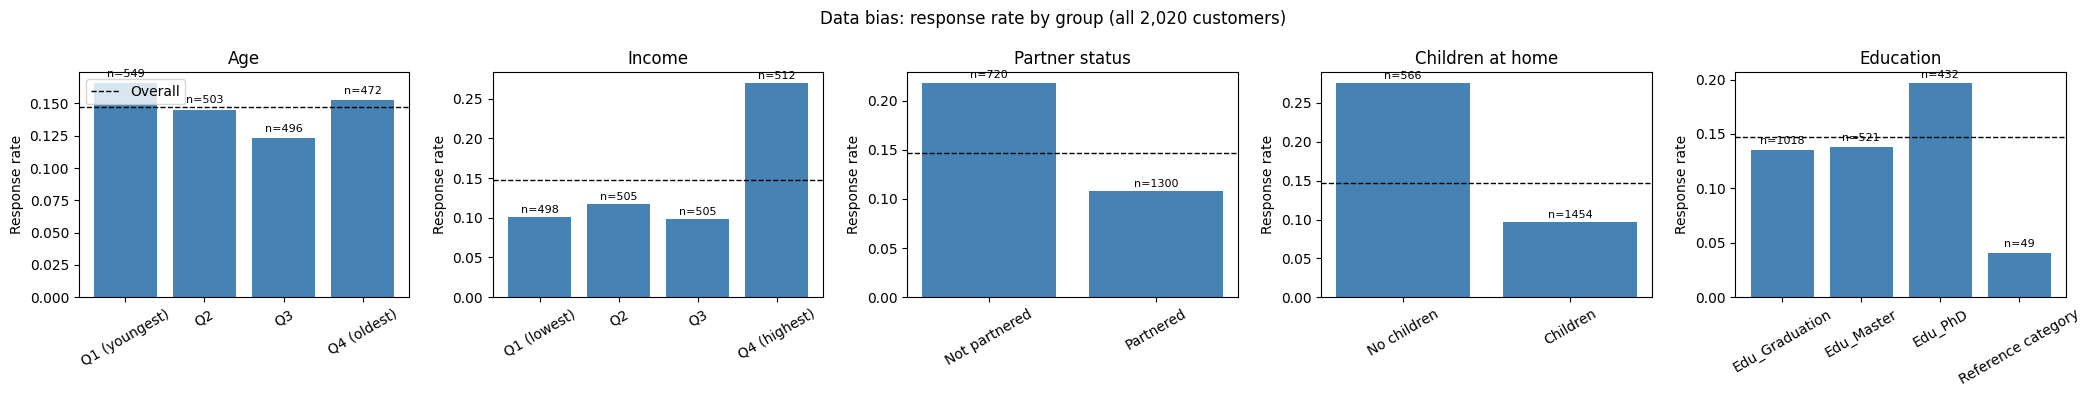

In [37]:
# Representation and response rate by group across the full labeled dataset
X_all = pd.concat([X_train, X_val, X_test], ignore_index=True)
y_all = pd.concat([y_train, y_val, y_test], ignore_index=True)
groups_all = pd.concat([groups_train, groups_val, groups_test], ignore_index=True)

data_bias_rows = []
for attr in groups_all.columns:
    g = groups_all[attr]
    contingency = pd.crosstab(g, y_all)
    chi2, p_value, _, _ = chi2_contingency(contingency)
    for level in g.cat.categories:
        mask = (g == level).to_numpy()
        data_bias_rows.append({
            "Attribute": attr,
            "Group": level,
            "Customers": int(mask.sum()),
            "Share of data": mask.mean(),
            "Responders": int(y_all[mask].sum()),
            "Response rate": y_all[mask].mean() if mask.any() else np.nan,
            "Chi-square p-value (attribute)": p_value,
        })
data_bias = pd.DataFrame(data_bias_rows).set_index(["Attribute", "Group"])
display(data_bias.round(4))

# Chart: response rate by group for each attribute, with the overall rate as a reference line
attrs = list(groups_all.columns)
fig, axes = plt.subplots(1, len(attrs), figsize=(4.2 * len(attrs), 4), squeeze=False)
for ax, attr in zip(axes[0], attrs):
    sub = data_bias.loc[attr]
    ax.bar(sub.index.astype(str), sub["Response rate"], color="steelblue")
    ax.axhline(y_all.mean(), color="black", ls="--", lw=1, label="Overall")
    for k, (rate, n) in enumerate(zip(sub["Response rate"], sub["Customers"])):
        ax.text(k, rate + 0.005, f"n={n}", ha="center", fontsize=8)
    ax.set_title(attr)
    ax.set_ylabel("Response rate")
    ax.tick_params(axis="x", rotation=30)
axes[0][0].legend()
plt.suptitle("Data bias: response rate by group (all 2,020 customers)")
plt.tight_layout()
plt.savefig(FIG_DIR / "week11_data_bias.png", dpi=150)
plt.show()

### Interpretation: data bias

- **Representation.**
  - Age and income groups are quartiles, so they are equal in size by construction.
  - Partnered customers make up 64% of the data, and customers with children at home 72%.
  - The education reference category (customers with none of the Graduation, Master or PhD flags) has only 49 customers (2.4%) and 2 responders, too few to evaluate reliably.
- **Response rates differ strongly by group**, and the differences are statistically significant for every attribute except age (chi-square p = 0.27):
  - **Income:** 27.0% in the highest quartile, against 9.9–11.7% in the other three.
  - **Partner status:** 21.8% for customers without a partner, against 10.8% for partnered customers.
  - **Children at home:** 27.6% without children, against 9.7% with children.
  - **Education:** 19.7% for PhD holders, against 13.6–13.8% for Graduation and Master.
- **Limits of the label.**
  - `Response` records acceptance of one specific campaign, so the group differences may reflect that campaign's offer design as much as how responsive each group is in general.
  - The data comes from a single company over 2012–2014 and may not represent its current customers.

### Model bias: targeting decisions by group

The model scores the holdout customers, the top 40% are selected, and every metric is computed within each group.

In [38]:
# Fairness metrics for one attribute at the top-40% decision rule
def wilson_interval(successes, n, z=1.96):
    # 95% confidence interval for a proportion; more reliable than the normal approximation for small n
    if n == 0:
        return np.nan, np.nan
    p = successes / n
    denom = 1 + z ** 2 / n
    centre = (p + z ** 2 / (2 * n)) / denom
    half = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / denom
    return centre - half, centre + half


def group_fairness(y, proba, group, share=TOP_SHARE):
    y = np.asarray(y)
    proba = np.asarray(proba)
    group = pd.Series(group).reset_index(drop=True)
    n_top = int(np.ceil(share * len(y)))
    selected = np.zeros(len(y), dtype=bool)
    selected[np.argsort(-proba)[:n_top]] = True

    rows = []
    for level in group.cat.categories:
        m = (group == level).to_numpy()
        if not m.any():
            continue
        yg, sg, pg = y[m], selected[m], proba[m]
        pos, neg = yg == 1, yg == 0
        tp = int((sg & pos).sum())
        low, high = wilson_interval(tp, int(pos.sum()))
        rows.append({
            "Group": level,
            "Customers": int(m.sum()),
            "Responders": int(pos.sum()),
            "Response rate": yg.mean(),
            "Mean predicted probability": pg.mean(),
            "Selection rate": sg.mean(),
            "TPR": tp / pos.sum() if pos.sum() else np.nan,
            "TPR 95% low": low,
            "TPR 95% high": high,
            "FPR": (sg & neg).sum() / neg.sum() if neg.sum() else np.nan,
            "Precision": tp / sg.sum() if sg.sum() else np.nan,
        })
    out = pd.DataFrame(rows).set_index("Group")
    out["Disparate impact ratio"] = out["Selection rate"] / out["Selection rate"].max()
    out["Calibration gap"] = out["Mean predicted probability"] - out["Response rate"]
    return out


def summarize_fairness(table):
    # One-line summary of an attribute: worst disparate impact, TPR gap (stable groups only), worst calibration gap
    stable = table[table["Responders"] >= MIN_RESPONDERS]
    tpr_gap = stable["TPR"].max() - stable["TPR"].min() if len(stable) >= 2 else np.nan
    return {
        "Lowest disparate impact ratio": table["Disparate impact ratio"].min(),
        "Group with lowest selection": table["Selection rate"].idxmin(),
        "TPR gap": tpr_gap,
        "Group with lowest TPR": stable["TPR"].idxmin() if len(stable) else None,
        "Largest |calibration gap|": table["Calibration gap"].abs().max(),
        "Fails four-fifths rule": bool(table["Disparate impact ratio"].min() < 0.8),
        "TPR gap > 0.10": bool(tpr_gap > 0.10) if not np.isnan(tpr_gap) else False,
    }


# Holdout = validation + test (neither was used to fit the model)
X_hold = pd.concat([X_val, X_test], ignore_index=True)
y_hold = pd.concat([y_val, y_test], ignore_index=True)
groups_hold = pd.concat([groups_val, groups_test], ignore_index=True)
proba_hold = model.predict_proba(X_hold)[:, 1]

fairness_tables = {attr: group_fairness(y_hold, proba_hold, groups_hold[attr]) for attr in groups_hold.columns}
for attr, table in fairness_tables.items():
    print(f"\n{attr}")
    display(table.round(3))

model_bias_summary = pd.DataFrame({attr: summarize_fairness(t) for attr, t in fairness_tables.items()}).T
print("\nModel bias summary (holdout, top-40% rule)")
display(model_bias_summary)


Age


,Customers,Responders,Response rate,Mean predicted probability,Selection rate,TPR,TPR 95% low,TPR 95% high,FPR,Precision,Disparate impact ratio,Calibration gap
Group,,,,,,,,,,,,
Q1 (youngest),204,32,0.157,0.147,0.417,0.938,0.799,0.983,0.320,0.353,0.998,-0.010
Q2,181,30,0.166,0.135,0.403,0.900,0.744,0.965,0.305,0.370,0.966,-0.031
Q3,179,21,0.117,0.112,0.363,0.905,0.711,0.973,0.291,0.292,0.869,-0.005
Q4 (oldest),170,27,0.159,0.144,0.418,0.815,0.633,0.918,0.343,0.310,1.000,-0.015



Income


,Customers,Responders,Response rate,Mean predicted probability,Selection rate,TPR,TPR 95% low,TPR 95% high,FPR,Precision,Disparate impact ratio,Calibration gap
Group,,,,,,,,,,,,
Q1 (lowest),176,17,0.097,0.095,0.398,1.000,0.816,1.000,0.333,0.243,0.727,-0.001
Q2,184,21,0.114,0.110,0.353,0.905,0.711,0.973,0.282,0.292,0.645,-0.004
Q3,184,23,0.125,0.092,0.299,0.783,0.581,0.903,0.230,0.327,0.546,-0.033
Q4 (highest),190,49,0.258,0.236,0.547,0.898,0.782,0.956,0.426,0.423,1.000,-0.022



Partner status


,Customers,Responders,Response rate,Mean predicted probability,Selection rate,TPR,TPR 95% low,TPR 95% high,FPR,Precision,Disparate impact ratio,Calibration gap
Group,,,,,,,,,,,,
Not partnered,269,54,0.201,0.210,0.535,0.963,0.875,0.99,0.428,0.361,1.000,0.009
Partnered,465,56,0.120,0.091,0.323,0.821,0.702,0.90,0.254,0.307,0.603,-0.029


... (2 outputs left out)


Education


,Customers,Responders,Response rate,Mean predicted probability,Selection rate,TPR,TPR 95% low,TPR 95% high,FPR,Precision,Disparate impact ratio,Calibration gap
Group,,,,,,,,,,,,
Edu_Graduation,365,55,0.151,0.130,0.381,0.927,0.827,0.971,0.284,0.367,0.844,-0.021
Edu_Master,204,24,0.118,0.141,0.451,0.917,0.742,0.977,0.389,0.239,1.000,0.023
Edu_PhD,147,30,0.204,0.141,0.374,0.800,0.627,0.905,0.265,0.436,0.830,-0.063
Reference category,18,1,0.056,0.117,0.444,1.000,0.207,1.000,0.412,0.125,0.986,0.061



Model bias summary (holdout, top-40% rule)


,Lowest disparate impact ratio,Group with lowest selection,TPR gap,Group with lowest TPR,Largest |calibration gap|,Fails four-fifths rule,TPR gap > 0.10
Age,0.869463,Q3,0.122685,Q4 (oldest),0.030846,False,True
Income,0.546091,Q3,0.217391,Q3,0.032714,True,True
Partner status,0.602599,Partnered,0.141534,Partnered,0.029022,True,True
Children at home,0.575435,Children,0.02,Children,0.040057,True,False
Education,0.829636,Edu_PhD,0.127273,Edu_PhD,0.062991,False,True


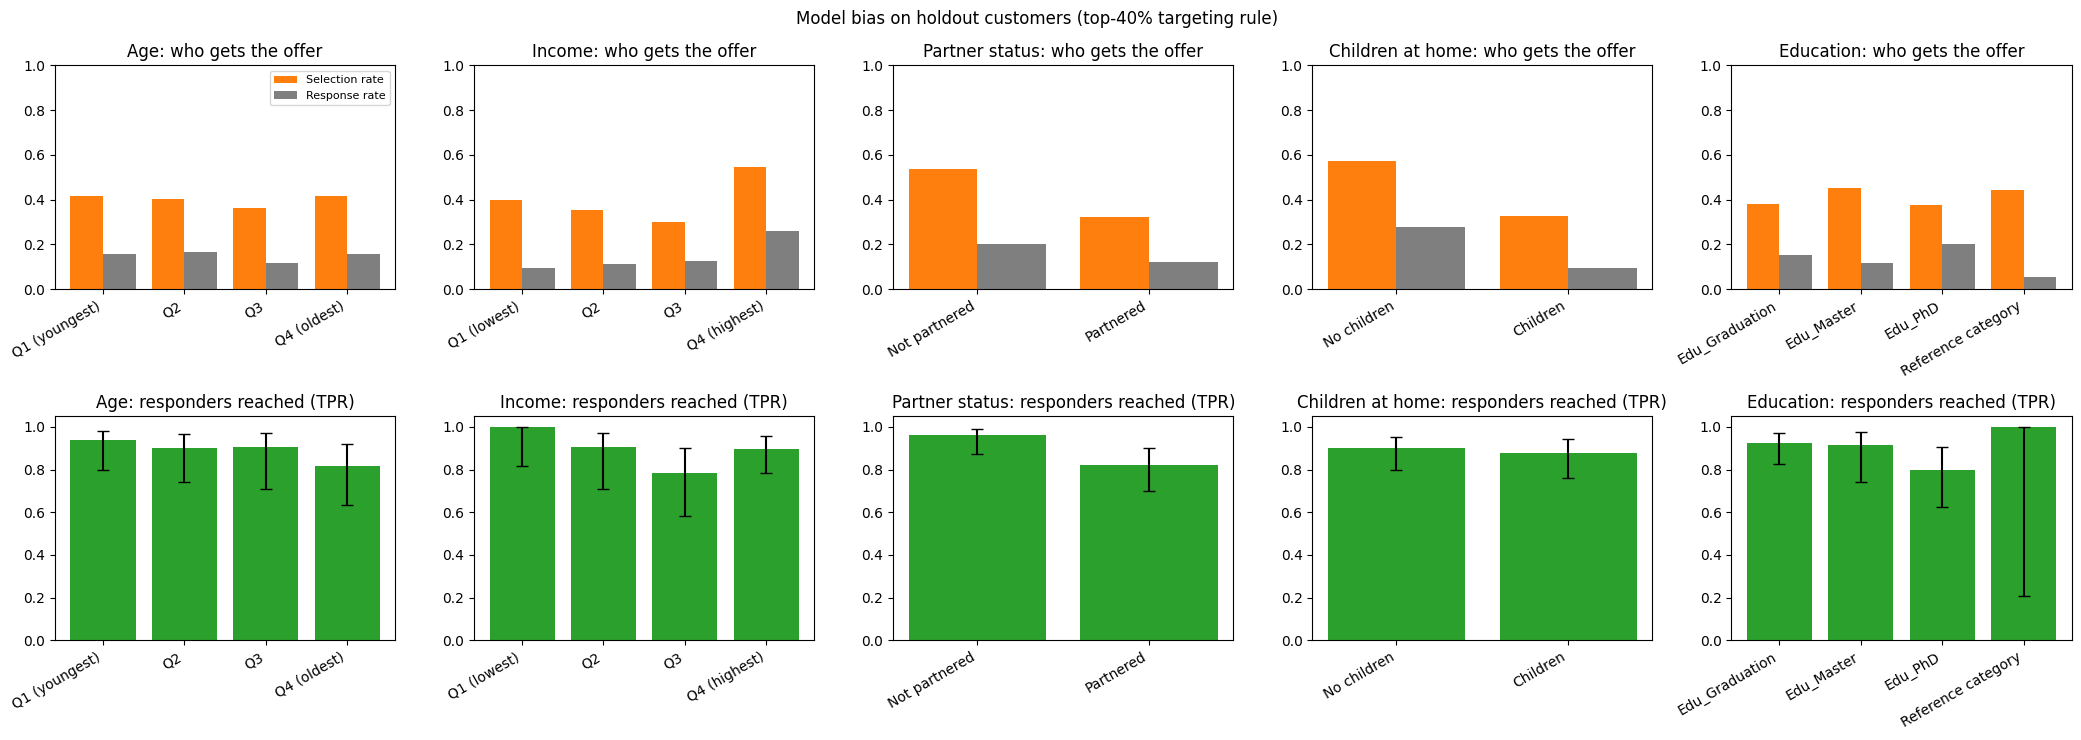

In [39]:
# Charts: selection rate vs response rate, and TPR with 95% intervals, for each attribute
attrs = list(fairness_tables)
fig, axes = plt.subplots(2, len(attrs), figsize=(4.2 * len(attrs), 7.5), squeeze=False)
for col, attr in enumerate(attrs):
    t = fairness_tables[attr]
    labels = t.index.astype(str)
    x = np.arange(len(t))

    ax = axes[0][col]
    ax.bar(x - 0.2, t["Selection rate"], 0.4, label="Selection rate", color="tab:orange")
    ax.bar(x + 0.2, t["Response rate"], 0.4, label="Response rate", color="tab:gray")
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=30, ha="right")
    ax.set_title(f"{attr}: who gets the offer")
    ax.set_ylim(0, 1)

    ax = axes[1][col]
    err = np.vstack([t["TPR"] - t["TPR 95% low"], t["TPR 95% high"] - t["TPR"]])
    ax.bar(x, t["TPR"], yerr=err, capsize=4, color="tab:green")
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=30, ha="right")
    ax.set_title(f"{attr}: responders reached (TPR)")
    ax.set_ylim(0, 1.05)
axes[0][0].legend(fontsize=8)
plt.suptitle("Model bias on holdout customers (top-40% targeting rule)")
plt.tight_layout()
plt.savefig(FIG_DIR / "week11_model_bias.png", dpi=150)
plt.show()

### Interpretation: model bias

- **Who receives the offer.** Under the top-40% rule, three attributes fail the four-fifths rule:
  - **Income:** the Q3 selection rate is 0.55 of the Q4 rate.
  - **Partner status:** partnered customers are selected at 0.60 of the rate of non-partnered customers (32% vs. 54%).
  - **Children at home:** customers with children are selected at 0.58 of the rate of those without (33% vs. 57%).
  - Age (0.87) and education (0.83) pass.
- **The selection gaps follow the response-rate gaps in the data** (orange bars track gray bars). The model ranks customers by how likely they are to respond, and those groups do respond less often.
- **Responders are reached at similar rates.** TPR (the share of each group's responders who receive the offer) ranges from 0.78 to 1.00. Every 95% interval overlaps the others, and the children-at-home gap is only 0.02. There is no clear evidence that a responder in one group is less likely to be reached than an equally responsive customer in another.
- **Calibration is good within groups:** predicted and actual response rates differ by at most 0.04, except PhD holders (the model under-predicts by 0.063).
- **Conclusion.** The model is accurate for every group, but it concentrates offers on high-income, non-partnered customers without children. Whether that is acceptable depends on what the offer is. If it is a discount or benefit, these groups systematically receive less of it, which is a fairness concern even though the predictions are accurate.

### Proxy check: can the other features reveal a customer's group?

Removing a sensitive column does not remove its information if other features predict it. For each attribute, a separate logistic regression tries to predict the customer's group from all *other* predictors, using 5-fold cross-validation on all 2,020 customers. A ROC-AUC near 0.5 means no proxy; values well above 0.5 mean the model can infer the group indirectly. Groups with fewer than 10 customers are left out of this test.

In [40]:
# Columns that directly encode each attribute; everything else is a potential proxy
own_columns = {
    "Age": ["Age"],
    "Income": ["Income"],
    "Partner status": ["Is_Partnered"],
    "Children at home": kid_cols,
    "Education": edu_cols,
}

proxy_rows = []
for attr in groups_all.columns:
    other_cols = [c for c in feature_names if c not in own_columns.get(attr, [])]
    g = groups_all[attr].astype(str)
    keep = g.map(g.value_counts()) >= 10
    Xp, gp = X_all.loc[keep, other_cols], g[keep].reset_index(drop=True)
    classes = np.sort(gp.unique())
    if len(classes) < 2:
        continue

    cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    proxy_model = LogisticRegression(max_iter=5000)
    proba_g = cross_val_predict(proxy_model, Xp, gp, cv=cv5, method="predict_proba")
    if len(classes) == 2:
        auc = roc_auc_score(gp == classes[1], proba_g[:, 1])
    else:
        auc = roc_auc_score(gp, proba_g, multi_class="ovr", labels=classes)

    # Strongest proxies: largest absolute coefficients when fit on all customers
    fitted = proxy_model.fit(Xp, gp)
    strength = pd.Series(np.abs(fitted.coef_).max(axis=0), index=other_cols).sort_values(ascending=False)
    proxy_rows.append({
        "Attribute": attr,
        "Proxy ROC-AUC (5-fold)": auc,
        "Strongest proxies": ", ".join(strength.index[:3]),
    })

proxy_table = pd.DataFrame(proxy_rows).set_index("Attribute")
display(proxy_table.round(3))

,Proxy ROC-AUC (5-fold),Strongest proxies
Attribute,,
Age,0.662,"Teenhome, Complain, Total_Spend"
Income,0.960,"Income_per_Person, Lives_Alone, Is_Partnered"
Partner status,0.981,"Income_per_Person, Income, Total_Purchases"
Children at home,0.999,"Income_per_Person, Income, Is_Partnered"
Education,0.725,"MntWines, MntMeatProducts, MntFishProducts"


### Interpretation: proxies

- **Household attributes can be reconstructed almost perfectly from the other predictors:**
  - Children at home: ROC-AUC 0.999.
  - Partner status: 0.981.
  - Income: 0.960.
- **The main proxy in all three cases is `Income_per_Person`.** It divides income by household size, so it encodes both income and household composition.
- **Age (0.66) and education (0.73)** are only weakly predictable, mainly through spending patterns.
- **Consequence for mitigation:** removing the `Is_Partnered`, `Kidhome`, `Teenhome` and `Lives_Alone` columns would not stop the model from using household status. `Income_per_Person` would carry the same information. Part 4 tests this directly.

In [41]:
# Bias summary across all checks, generated from the results above
print("BIAS SUMMARY")
for attr in groups_all.columns:
    d = data_bias.loc[attr]
    s = model_bias_summary.loc[attr]
    print(f"\n{attr}")
    print(f"  Data: smallest group {d['Customers'].idxmin()} ({d['Share of data'].min():.1%} of customers); "
          f"response rate ranges {d['Response rate'].min():.3f} to {d['Response rate'].max():.3f} "
          f"(chi-square p = {d['Chi-square p-value (attribute)'].iloc[0]:.4f})")
    print(f"  Model: lowest disparate impact ratio {s['Lowest disparate impact ratio']:.2f} "
          f"({s['Group with lowest selection']}); TPR gap {s['TPR gap']:.3f} "
          f"(lowest: {s['Group with lowest TPR']})")
    flags = [name for name in ["Fails four-fifths rule", "TPR gap > 0.10"] if s[name]]
    print("  Flags:", ", ".join(flags) if flags else "none")
    if attr in proxy_table.index:
        print(f"  Proxy ROC-AUC {proxy_table.loc[attr, 'Proxy ROC-AUC (5-fold)']:.3f} "
              f"(strongest proxies: {proxy_table.loc[attr, 'Strongest proxies']})")

BIAS SUMMARY

Age
  Data: smallest group Q4 (oldest) (23.4% of customers); response rate ranges 0.123 to 0.166 (chi-square p = 0.2668)
  Model: lowest disparate impact ratio 0.87 (Q3); TPR gap 0.123 (lowest: Q4 (oldest))
  Flags: TPR gap > 0.10
  Proxy ROC-AUC 0.662 (strongest proxies: Teenhome, Complain, Total_Spend)

Income
  Data: smallest group Q1 (lowest) (24.7% of customers); response rate ranges 0.099 to 0.270 (chi-square p = 0.0000)
  Model: lowest disparate impact ratio 0.55 (Q3); TPR gap 0.217 (lowest: Q3)
  Flags: Fails four-fifths rule, TPR gap > 0.10
  Proxy ROC-AUC 0.960 (strongest proxies: Income_per_Person, Lives_Alone, Is_Partnered)

Partner status
  Data: smallest group Not partnered (35.6% of customers); response rate ranges 0.108 to 0.218 (chi-square p = 0.0000)
  Model: lowest disparate impact ratio 0.60 (Partnered); TPR gap 0.142 (lowest: Partnered)
  Flags: Fails four-fifths rule, TPR gap > 0.10
  Proxy ROC-AUC 0.981 (strongest proxies: Income_per_Person, Income,

## Part 4 : Treat the Data to Reduce Bias and Retrain

**Which bias to target.** Part 3 found that the persistent bias is in *who receives the offer*. Income, partner status and children at home fail the four-fifths rule on disparate impact. Gaps in responders reached (TPR) are small and overlap within their confidence intervals. The treatments below therefore aim to raise the **disparate impact ratio**.

**Treatments tested** (all on top of the Week 10 capping, with the same model settings: logistic regression, C = 3, liblinear):

1. **Remove sensitive features** ("fairness through unawareness"): drop predictors that directly encode age, partner or household status, children, and education.
2. **Remove sensitive features + the household proxy:** also drop `Income_per_Person`. The proxy check identified it as the main feature through which partner and children status leak back in (it divides income by household size).
3. **Reweighing** (Kamiran and Calders, 2012): training customers are weighted so that the target attribute and response become statistically independent. The weight for group g and outcome y is P(g)·P(y) / P(g, y).
4. **Treatment 2 + reweighing.**

Income itself is kept in every version because it is central to the business question. Its fairness is still measured through the income groups.

**Selection rule, using no holdout data for the choice:**
- The attribute to reweigh is the one with the **lowest disparate impact ratio** on out-of-fold training predictions, where each training customer is scored by a model that did not see them.
- Each treatment's **fairness score** is the average, across the five attributes, of the lowest disparate impact ratio on out-of-fold training predictions. Higher is fairer, and 1.0 means every group is selected at the same rate.
- **Eligible** treatments keep validation PR-AUC within 0.02 of Week 10. Among them, the one with the highest fairness score is selected. If none is eligible, the fairest treatment is still reported and the performance cost is stated.
- The test data is used only to report the final comparison.

In [42]:
# Feature lists for the treatments, and the helper functions used to train and evaluate them
household_names = ["Age", "Is_Partnered", "Lives_Alone", "Kidhome", "Teenhome", "Total_Children",
                   "Children", "Has_Children", "Is_Parent", "Family_Size", "Household_Size"]
sensitive_features = [c for c in feature_names if c in household_names] + edu_cols
household_proxies = [c for c in ["Income_per_Person"] if c in feature_names]
kept_features = [c for c in feature_names if c not in sensitive_features]
kept_no_proxy = [c for c in kept_features if c not in household_proxies]
print("Sensitive features removed:", sensitive_features)
print("Household proxy removed in treatments 2 and 4:", household_proxies)
print(f"Predictors used: treatment 1 = {len(kept_features)}, treatments 2 and 4 = {len(kept_no_proxy)}, "
      f"treatment 3 = {len(feature_names)} (all)")


def reweighing_weights(y, group):
    # Kamiran and Calders reweighing: w(g, y) = P(g) * P(y) / P(g, y)
    df = pd.DataFrame({"y": np.asarray(y), "g": np.asarray(group).astype(str)})
    p_y = df["y"].value_counts(normalize=True)
    p_g = df["g"].value_counts(normalize=True)
    p_gy = df.groupby(["g", "y"]).size() / len(df)
    return np.array([p_g[g] * p_y[y_] / p_gy[(g, y_)] for g, y_ in zip(df["g"], df["y"])])


def out_of_fold_proba(features, reweigh_group=None, n_splits=5):
    # Each training customer is scored by a model fit without them; weights are computed inside each fold
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=RANDOM_STATE)
    oof = np.zeros(len(y_train))
    for tr, te in skf.split(X_train, y_train):
        m = clone(model)
        w = None if reweigh_group is None else reweighing_weights(y_train.iloc[tr], reweigh_group.iloc[tr])
        m.fit(X_train.iloc[tr][features], y_train.iloc[tr], sample_weight=w)
        oof[te] = m.predict_proba(X_train.iloc[te][features])[:, 1]
    return oof


def fairness_overview(y, proba, groups):
    # One summary row per attribute (lowest disparate impact ratio, TPR gap, calibration gap, flags)
    return pd.DataFrame({
        attr: summarize_fairness(group_fairness(y, proba, groups[attr])) for attr in groups.columns
    }).T


# Out-of-fold fairness of the Week 10 configuration on the training data; picks the attribute to reweigh
oof_week10 = out_of_fold_proba(feature_names)
oof_week10_summary = fairness_overview(y_train, oof_week10, groups_train)
display(oof_week10_summary)
target_attr = oof_week10_summary["Lowest disparate impact ratio"].astype(float).idxmin()
print("Attribute selected for reweighing (lowest out-of-fold disparate impact ratio):", target_attr)

Sensitive features removed: ['Kidhome', 'Teenhome', 'Is_Partnered', 'Age', 'Lives_Alone', 'Edu_Graduation', 'Edu_Master', 'Edu_PhD']
Household proxy removed in treatments 2 and 4: ['Income_per_Person']
Predictors used: treatment 1 = 19, treatments 2 and 4 = 18, treatment 3 = 27 (all)


,Lowest disparate impact ratio,Group with lowest selection,TPR gap,Group with lowest TPR,Largest |calibration gap|,Fails four-fifths rule,TPR gap > 0.10
Age,0.645404,Q3,0.041102,Q3,0.010069,True,False
Income,0.621814,Q2,0.07496,Q2,0.021312,True,False
Partner status,0.555005,Partnered,0.054207,Partnered,0.005468,True,False
Children at home,0.558698,Children,0.067079,Children,0.004786,True,False
Education,0.740582,Edu_Graduation,0.026136,Edu_Master,0.076609,True,False


Attribute selected for reweighing (lowest out-of-fold disparate impact ratio): Partner status


### Interpretation: out-of-fold fairness on the training data

On out-of-fold training predictions, all five attributes fall below the four-fifths threshold, with partner status the lowest (0.555), followed by children at home (0.559). TPR gaps are all below 0.08, which confirms that the bias to address is in selection, not in which responders are reached. Partner status is therefore the attribute chosen for reweighing.

In [43]:
# Fit every treatment, then record performance (training, validation, test) and fairness
# (out-of-fold on training data for selection; holdout for reporting)
variants = {
    "1. Remove sensitive features": dict(features=kept_features, reweigh=False),
    "2. Remove sensitive features + household proxy": dict(features=kept_no_proxy, reweigh=False),
    "3. Reweighing": dict(features=feature_names, reweigh=True),
    "4. Remove sensitive + household proxy + reweighing": dict(features=kept_no_proxy, reweigh=True),
}

fitted_variants = {"Week 10 model (reference)": (model, feature_names)}
oof_summaries = {"Week 10 model (reference)": oof_week10_summary}
holdout_summaries = {"Week 10 model (reference)": model_bias_summary}

for name, cfg in variants.items():
    feats = cfg["features"]
    weights = reweighing_weights(y_train, groups_train[target_attr]) if cfg["reweigh"] else None
    m = clone(model).fit(X_train[feats], y_train, sample_weight=weights)
    fitted_variants[name] = (m, feats)
    oof = out_of_fold_proba(feats, groups_train[target_attr] if cfg["reweigh"] else None)
    oof_summaries[name] = fairness_overview(y_train, oof, groups_train)
    holdout_summaries[name] = fairness_overview(y_hold, m.predict_proba(X_hold[feats])[:, 1], groups_hold)

rows = []
for name, (m, feats) in fitted_variants.items():
    oof_di = oof_summaries[name]["Lowest disparate impact ratio"].astype(float)
    hold_di = holdout_summaries[name]["Lowest disparate impact ratio"].astype(float)
    rows.append({
        "Version": name,
        "Predictors": len(feats),
        "Training PR-AUC": average_precision_score(y_train, m.predict_proba(X_train[feats])[:, 1]),
        "Validation PR-AUC": average_precision_score(y_val, m.predict_proba(X_val[feats])[:, 1]),
        "Test PR-AUC": average_precision_score(y_test, m.predict_proba(X_test[feats])[:, 1]),
        "Validation top-40% capture": top_share_capture(y_val, m.predict_proba(X_val[feats])[:, 1]),
        "OOF fairness score (mean lowest DI)": oof_di.mean(),
        "OOF worst DI": oof_di.min(),
        "Holdout fairness score (mean lowest DI)": hold_di.mean(),
        "Holdout attributes failing four-fifths": int((hold_di < 0.8).sum()),
    })
variant_results = pd.DataFrame(rows).set_index("Version")
display(variant_results.round(4))

,Predictors,Training PR-AUC,Validation PR-AUC,Test PR-AUC,Validation top-40% capture,OOF fairness score (mean lowest DI),OOF worst DI,Holdout fairness score (mean lowest DI),Holdout attributes failing four-fifths
Version,,,,,,,,,
Week 10 model (reference),27,0.7691,0.7268,0.6780,0.9149,0.6243,0.5550,0.6846,3
1. Remove sensitive features,19,0.7545,0.7375,0.6541,0.9149,0.6548,0.5366,0.6911,4
2. Remove sensitive features + household proxy,18,0.6746,0.6392,0.6081,0.9362,0.7472,0.5622,0.7724,3
3. Reweighing,27,0.7541,0.7190,0.6708,0.9362,0.6672,0.5453,0.6962,4
4. Remove sensitive + household proxy + reweighing,18,0.6756,0.6381,0.5927,0.9149,0.7367,0.6076,0.7810,3


### Interpretation: the four treatments

- **1. Removing the sensitive features** barely changes fairness (out-of-fold score 0.624 → 0.655), and the holdout shows *four* attributes failing instead of three. As the proxy check predicted, the model recovers household information through the remaining features.
- **2. Also removing `Income_per_Person`** gives the largest fairness gain (0.747). It costs 0.088 in validation PR-AUC, however, because this feature is the third most important predictor. It falls outside the 0.02 tolerance.
- **3. Reweighing on partner status** raises the fairness score to 0.667, with validation PR-AUC within 0.008 of Week 10. It is the only treatment that improves fairness within the performance tolerance.
- **4. Combining proxy removal with reweighing** behaves like treatment 2: fairer (0.737), but too costly in accuracy (validation PR-AUC 0.638).

The pattern shows the core trade-off. The features that carry household information are also among the most predictive, so removing them buys fairness at a direct cost in accuracy.

In [44]:
# Selection rule: validation PR-AUC within 0.02 of Week 10, then the highest out-of-fold fairness score
tolerance = 0.02
week10_val_pr = week10_table.loc["PR-AUC", "Validation"]
score_col = "OOF fairness score (mean lowest DI)"

treated = variant_results.drop(index="Week 10 model (reference)")
eligible = treated[treated["Validation PR-AUC"] >= week10_val_pr - tolerance]
pool = eligible if len(eligible) else treated
final_name = pool.sort_values([score_col, "Validation PR-AUC"], ascending=[False, False]).index[0]
final_model, final_features = fitted_variants[final_name]

print(f"Selected treatment: {final_name}")
print("Meets the 0.02 validation PR-AUC tolerance:", final_name in eligible.index)
print(f"Out-of-fold fairness score: {variant_results.loc['Week 10 model (reference)', score_col]:.3f} -> "
      f"{variant_results.loc[final_name, score_col]:.3f}")
print(f"Validation PR-AUC: {week10_val_pr:.4f} -> {variant_results.loc[final_name, 'Validation PR-AUC']:.4f}")

Selected treatment: 3. Reweighing
Meets the 0.02 validation PR-AUC tolerance: True
Out-of-fold fairness score: 0.624 -> 0.667
Validation PR-AUC: 0.7268 -> 0.7190


Week 10                    Week 11 (bias-treated)             \
                Training Validation    Test               Training Validation   
PR-AUC            0.7691     0.7268  0.6780                 0.7541     0.7190   
ROC-AUC           0.9464     0.9091  0.8923                 0.9422     0.9143   
Precision         0.7895     0.7353  0.7179                 0.7597     0.7857   
Recall            0.5615     0.5319  0.4444                 0.5241     0.4681   
F1                0.6562     0.6173  0.5490                 0.6203     0.5867   
Log loss          0.2013     0.2370  0.2748                 0.2086     0.2360   
Top-40% capture   0.9733     0.9149  0.8571                 0.9679     0.9362   

                          Change                     
                   Test Training Validation    Test  
PR-AUC           0.6708  -0.0150    -0.0078 -0.0073  
ROC-AUC          0.8902  -0.0042     0.0052 -0.0021  
Precision        0.6444  -0.0298     0.0504 -0.0735  
Recall           0.4603  -0.0374    -0.0638  0.0159  
F1               0.5370  -0.0360    -0.0306 -0.0120  
Log loss         0.2754   0.0073    -0.0010  0.0006  
Top-40% capture  0.8889  -0.0053     0.0213  0.0317

Week 10          \
                 Lowest disparate impact ratio TPR gap   
Age                                      0.869   0.123   
Income                                   0.546   0.217   
Partner status                           0.603   0.142   
Children at home                         0.575   0.020   
Education                                0.830   0.127   

                                                                 Week 11  \
                 Largest |calibration gap| Lowest disparate impact ratio   
Age                                  0.031                         0.796   
Income                               0.033                         0.536   
Partner status                       0.029                         0.851   
Children at home                     0.040                         0.575   
Education                            0.063                         0.723   

                                                    
                 TPR gap Largest |calibration gap|  
Age                0.185                     0.026  
Income             0.217                     0.031  
Partner status     0.069                     0.030  
Children at home   0.090                     0.045  
Education          0.125                     0.068

Response rate  Selection rate (Week 10)  \
Attribute        Group                                                         
Age              Q1 (youngest)               0.157                     0.417   
                 Q2                          0.166                     0.403   
                 Q3                          0.117                     0.363   
                 Q4 (oldest)                 0.159                     0.418   
Income           Q1 (lowest)                 0.097                     0.398   
                 Q2                          0.114                     0.353   
                 Q3                          0.125                     0.299   
                 Q4 (highest)                0.258                     0.547   
Partner status   Not partnered               0.201                     0.535   
                 Partnered                   0.120                     0.323   
Children at home No children                 0.276                     0.571   
                 Children                    0.097                     0.329   
Education        Edu_Graduation              0.151                     0.381   
                 Edu_Master                  0.118                     0.451   
                 Edu_PhD                     0.204                     0.374   
                 Reference category          0.056                     0.444   

                                     Selection rate (Week 11)  \
Attribute        Group                                          
Age              Q1 (youngest)                          0.417   
                 Q2                                     0.403   
                 Q3                                     0.346   
                 Q4 (oldest)                            0.435   
Income           Q1 (lowest)                            0.375   
                 Q2                                     0.364   
                 Q3                                     0.299   
                 Q4 (highest)                           0.558   
Partner status   Not partnered                          0.442   
                 Partnered                              0.376   
Children at home No children                            0.571   
                 Children                               0.329   
Education        Edu_Graduation                         0.359   
                 Edu_Master                             0.461   
                 Edu_PhD                                0.429   
                 Reference category                     0.333   

                                     Precision (Week 10)  Precision (Week 11)  
Attribute        Group                                                         
Age              Q1 (youngest)                     0.353                0.376  
                 Q2                                0.370                0.370  
                 Q3                                0.292                0.306  
                 Q4 (oldest)                       0.310                0.297  
Income           Q1 (lowest)                       0.243                0.258  
                 Q2                                0.292                0.269  
                 Q3                                0.327                0.327  
                 Q4 (highest)                      0.423                0.443  
Partner status   Not partnered                     0.361                0.429  
                 Partnered                         0.307                0.280  
Children at home No children                       0.435                0.460  
                 Children                          0.259                0.253  
Education        Edu_Graduation                    0.367                0.389  
                 Edu_Master                        0.239                0.245  
                 Edu_PhD                           0.436                0.397  
                 Reference category                0.125         

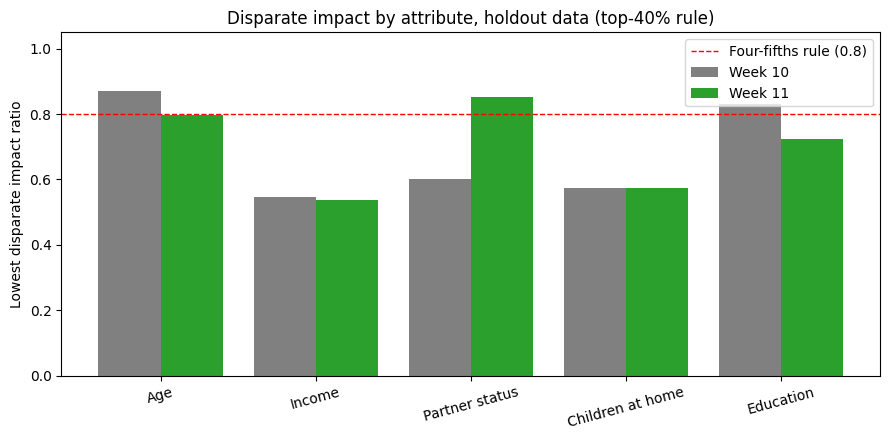

In [45]:
# Required comparison: training, validation and test metrics for the bias-treated model vs Week 10
week11_table = pd.DataFrame({
    "Training": score_dataset(final_model, X_train[final_features], y_train),
    "Validation": score_dataset(final_model, X_val[final_features], y_val),
    "Test": score_dataset(final_model, X_test[final_features], y_test),
})
comparison = pd.concat(
    {"Week 10": week10_table, "Week 11 (bias-treated)": week11_table, "Change": week11_table - week10_table},
    axis=1,
)
display(comparison.round(4))

# Fairness before and after on the holdout data, for every attribute
cols = ["Lowest disparate impact ratio", "TPR gap", "Largest |calibration gap|"]
before_after = pd.concat({
    "Week 10": holdout_summaries["Week 10 model (reference)"][cols],
    "Week 11": holdout_summaries[final_name][cols],
}, axis=1).astype(float)
display(before_after.round(3))

# Selection rate by group before and after, for every attribute (holdout, top-40% rule)
proba_hold_final = final_model.predict_proba(X_hold[final_features])[:, 1]
selection_rows = []
for attr in groups_hold.columns:
    before_t = fairness_tables[attr]
    after_t = group_fairness(y_hold, proba_hold_final, groups_hold[attr])
    for group in before_t.index:
        selection_rows.append({
            "Attribute": attr, "Group": group, "Response rate": before_t.loc[group, "Response rate"],
            "Selection rate (Week 10)": before_t.loc[group, "Selection rate"],
            "Selection rate (Week 11)": after_t.loc[group, "Selection rate"],
            "Precision (Week 10)": before_t.loc[group, "Precision"],
            "Precision (Week 11)": after_t.loc[group, "Precision"],
        })
display(pd.DataFrame(selection_rows).set_index(["Attribute", "Group"]).round(3))

# Chart: lowest disparate impact ratio per attribute, before and after, against the four-fifths line
x = np.arange(len(before_after))
plt.figure(figsize=(9, 4.5))
plt.bar(x - 0.2, before_after[("Week 10", "Lowest disparate impact ratio")], 0.4, label="Week 10", color="gray")
plt.bar(x + 0.2, before_after[("Week 11", "Lowest disparate impact ratio")], 0.4, label="Week 11", color="tab:green")
plt.axhline(0.8, color="red", ls="--", lw=1, label="Four-fifths rule (0.8)")
plt.xticks(x, before_after.index, rotation=15)
plt.ylabel("Lowest disparate impact ratio")
plt.ylim(0, 1.05)
plt.title("Disparate impact by attribute, holdout data (top-40% rule)")
plt.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "week11_mitigation_disparate_impact.png", dpi=150)
plt.show()

### Interpretation: Week 11 compared with Week 10

**Performance.** The reweighed model is close to Week 10 on every dataset.
- PR-AUC is 0.015 lower on training, 0.008 lower on validation and 0.007 lower on test.
- ROC-AUC changes by at most 0.005.
- Top-40% capture, the measure tied to how the campaign is actually run, *improves* on validation (0.915 → 0.936) and test (0.857 → 0.889). The reweighed model finds two more of the 63 test responders within the contacted 40%.
- At the 0.5 cutoff, test precision falls from 0.718 to 0.644 and test recall rises slightly (0.444 → 0.460).

**Fairness on the holdout data.**
- **Partner status, the targeted attribute, now passes:** disparate impact rose from 0.60 to 0.85. The share of partnered customers receiving the offer rose from 32% to 38%, and the share of non-partnered customers fell from 54% to 44%. The TPR gap halved, from 0.142 to 0.069.
- **Side effects on other attributes:**
  - Age fell from 0.87 to 0.80. At 0.796, it is just below the threshold.
  - Education fell from 0.83 to 0.72.
  - Income (0.55) and children at home (0.58) are unchanged.
  - Children at home did not improve, even though it is strongly linked to partner status: selection rates for customers with and without children stayed at 33% and 57%.
- **Cost for partnered customers:** precision among them fell from 0.307 to 0.280, because more partnered customers with lower response likelihood are now contacted.

**Conclusion.** Reweighing removed the largest single disparity at almost no cost in performance, but it did not remove bias overall. Four of the five attributes still fail the four-fifths rule on the holdout data. Correcting for one attribute moved the disparities onto others. Remaining disparities in income and children at home largely reflect genuine response-rate differences, and closing them would mean contacting customers the model expects to respond less. That is a business and ethical decision, not only a modeling one.

Possible next steps:
- reweighing on combined groups (for example, partner status × children at home);
- setting a separate selection threshold for each group;
- deciding explicitly which attributes the campaign must treat equally.

In [46]:
# Save the Week 11 model with its predictor list and the treatment applied
joblib.dump(
    {
        "model": final_model,
        "features": final_features,
        "treatment_name": final_name,
        "reweighed_attribute": target_attr if "reweighing" in final_name.lower() else None,
        "week10_capping": week10.get("treatment"),
        "name": f"Week 11 {model_name} | bias treatment: {final_name}",
    },
    MODEL_DIR / "week11_final_model.joblib",
)

print("WEEK 11 SUMMARY")
print(f"Model settings held constant: {model_name}")
print(f"Bias treatment selected: {final_name}")
for split in ["Training", "Validation", "Test"]:
    print(f"{split}: PR-AUC {week10_table.loc['PR-AUC', split]:.4f} -> {week11_table.loc['PR-AUC', split]:.4f}, "
          f"top-40% capture {week10_table.loc['Top-40% capture', split]:.3f} -> "
          f"{week11_table.loc['Top-40% capture', split]:.3f}")
for attr in before_after.index:
    print(f"{attr}: lowest disparate impact ratio "
          f"{before_after.loc[attr, ('Week 10', 'Lowest disparate impact ratio')]:.2f} -> "
          f"{before_after.loc[attr, ('Week 11', 'Lowest disparate impact ratio')]:.2f}")

WEEK 11 SUMMARY
Model settings held constant: Week 10 W6 Logistic regression with data treatment: Cap continuous features
Bias treatment selected: 3. Reweighing
Training: PR-AUC 0.7691 -> 0.7541, top-40% capture 0.973 -> 0.968
Validation: PR-AUC 0.7268 -> 0.7190, top-40% capture 0.915 -> 0.936
Test: PR-AUC 0.6780 -> 0.6708, top-40% capture 0.857 -> 0.889
Age: lowest disparate impact ratio 0.87 -> 0.80
Income: lowest disparate impact ratio 0.55 -> 0.54
Partner status: lowest disparate impact ratio 0.60 -> 0.85
Children at home: lowest disparate impact ratio 0.58 -> 0.58
Education: lowest disparate impact ratio 0.83 -> 0.72


## Model risk

| Risk | Description | Evidence in this analysis | Mitigation / monitoring |
|---|---|---|---|
| Unequal access to offers | High-income customers without a partner or children receive offers far more often | Disparate impact 0.55–0.60 for income, partner status and children (Week 10 model) | Track disparate impact per group for each campaign; reweighing as in Part 4; set an explicit fairness policy for discount-type offers |
| Proxy discrimination | Household status reaches the model through `Income_per_Person` even when direct columns are removed | Proxy ROC-AUC 0.98–0.999 for partner status and children | Audit proxies at each retraining; do not rely on removing columns |
| Feedback loop | Customers who are never contacted can never appear as responders in future training data, so under-selected groups can fall further behind | Selection rates of 32–33% for partnered customers and those with children | Keep a small randomized control group that is contacted regardless of score |
| Dependence on past campaign behavior | The model leans heavily on previous acceptances, so it is weakest for new or never-converted customers | `Total_Prev_Accepted` drives 0.36 of PR-AUC; the worst missed responder had no acceptance history | Monitor recall separately for customers with no previous acceptances |
| Data drift and age of data | Training data covers 2012–2014 from one company; customer behavior and channels change | Not testable here | Monitor input distributions and PR-AUC on each new campaign; retrain on recent data |
| Small sample and unstable estimates | 2,020 customers, about 300 responders; some groups have few responders | Wide TPR intervals; education reference group has 2 responders | Report confidence intervals; avoid group-level conclusions below about 10 responders |
| Privacy | Income, household composition and education are personal data | All are model inputs | Data minimization (drop features that add little accuracy, such as `Age`, `Teenhome`, `Edu_Master`); access controls |
| Misreading the model | Individual coefficients have counterintuitive signs because of correlated features | Negative coefficients on `Total_Spend` and `Total_Purchases` | Explain predictions with per-customer contributions, not single coefficients |

## WEEK 11 - END